In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA


DATA PREPROCESSING

In [78]:
# Load the data
col_mat_nuw_df = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/col_mat_nuw_output.csv", names=["HCHO reading", "Location", "Current Date", "Next Date"])
mon_kur_jaf_df = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/mon_kur_jaf_output.csv", names=["HCHO reading", "Location", "Current Date", "Next Date"])
kan_df = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/kan_output.csv", names=["HCHO reading", "Location", "Current Date", "Next Date"])

# Concatenate all datasets
data = pd.concat([col_mat_nuw_df, mon_kur_jaf_df, kan_df])

# Remove the 'Next Date' column
data.drop(columns=['Next Date'], inplace=True)

data.to_csv('concat_dataset.csv', index=False)

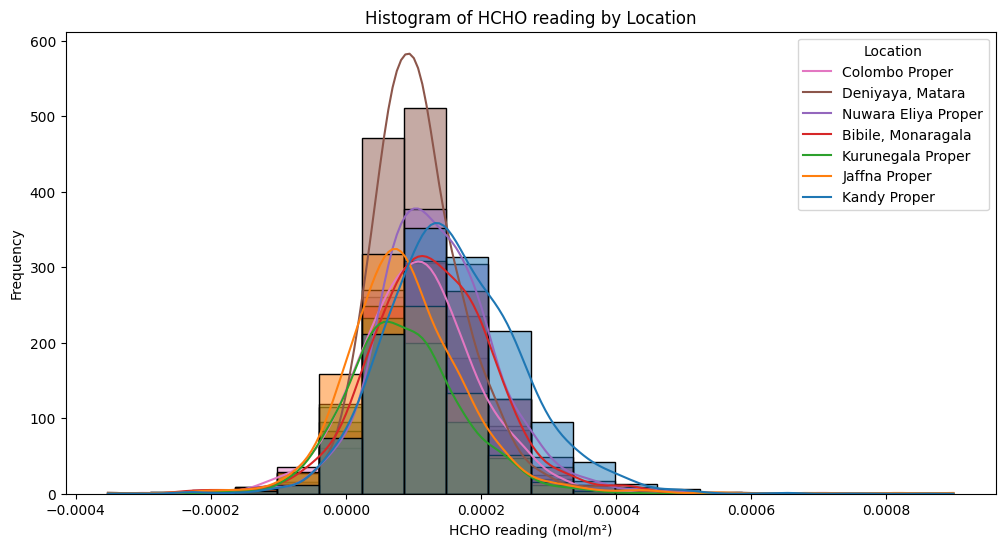

In [79]:
# Reset index to avoid duplicate labels
data.reset_index(drop=True, inplace=True)

# Get unique locations for legend labels
locations = data['Location'].unique()

# Histograms by location
plt.figure(figsize=(12, 6))
sns.histplot(data=data, x='HCHO reading', hue='Location', bins=20, kde=True, legend=True, hue_order=locations)
plt.title('Histogram of HCHO reading by Location')
plt.xlabel('HCHO reading (mol/m²)')
plt.ylabel('Frequency')
plt.legend(title='Location', labels=locations)
plt.show()

<ipython-input-80-80827282d34d>:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=data, x='Year', y='HCHO reading', hue='Location', palette='tab10', ci=None)


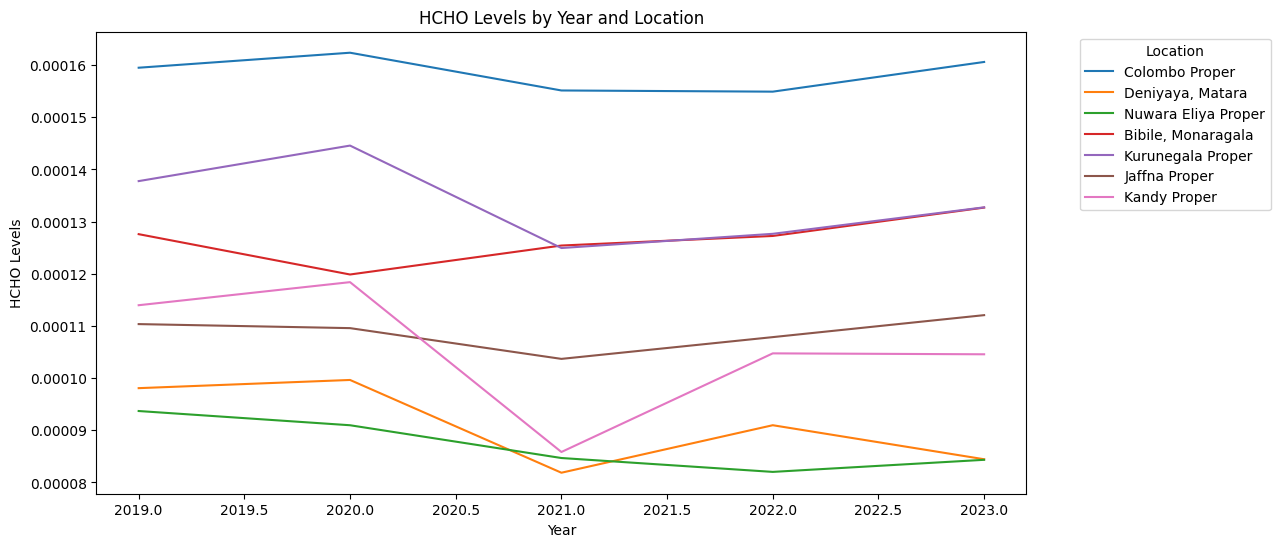

In [80]:
# Extract the year from the 'Current Date' column
data['Year'] = pd.to_datetime(data['Current Date']).dt.year.astype(int)

# Plot HCHO levels versus year, differentiating by location
plt.figure(figsize=(12, 6))
sns.lineplot(data=data, x='Year', y='HCHO reading', hue='Location', palette='tab10', ci=None)
plt.title('HCHO Levels by Year and Location')
plt.xlabel('Year')
plt.ylabel('HCHO Levels')
plt.legend(title='Location', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

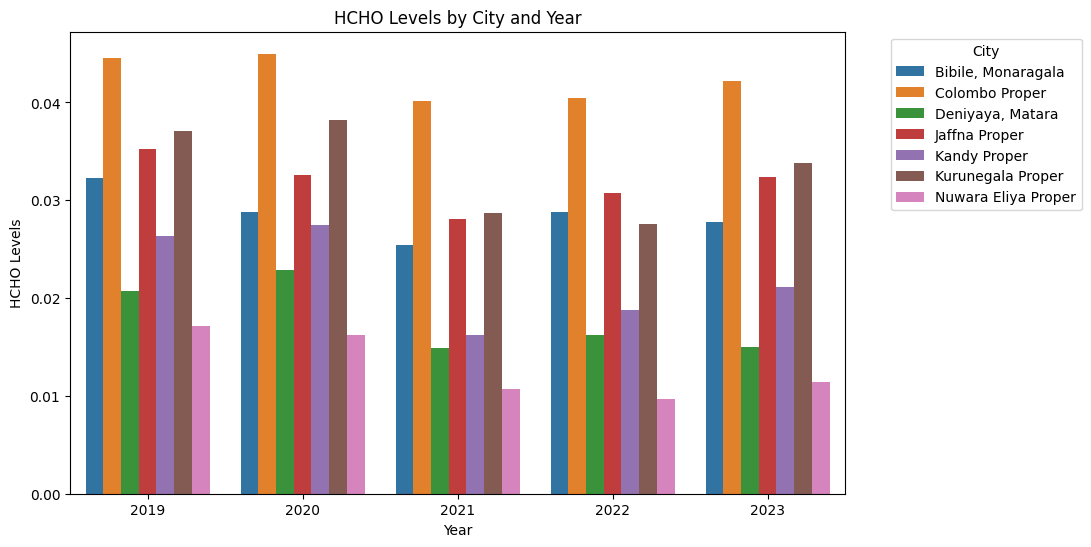

In [81]:
# Convert "Date" column to datetime format
data['Date'] = pd.to_datetime(data['Current Date'])

# Extract year from the "Date" column
data['Year'] = data['Date'].dt.year

# Group by City and Year and calculate the total HCHO levels
hcho_by_city_year = data.groupby(['Location', 'Year'])['HCHO reading'].sum().reset_index()

# Plotting using seaborn
plt.figure(figsize=(10, 6))
sns.barplot(data=hcho_by_city_year, x='Year', y='HCHO reading', hue='Location')
plt.title('HCHO Levels by City and Year')
plt.xlabel('Year')
plt.ylabel('HCHO Levels')
plt.legend(title='City', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

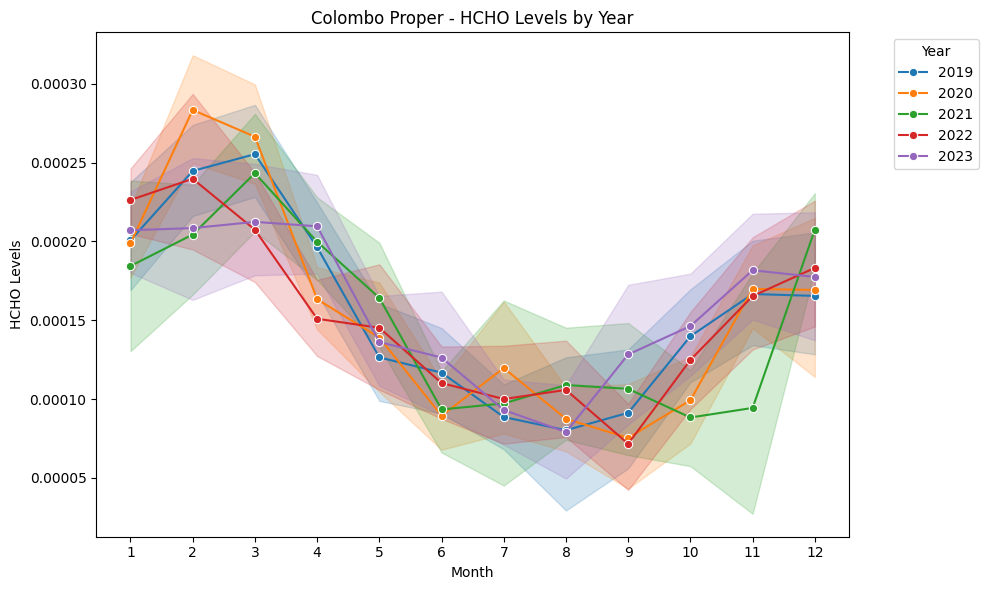

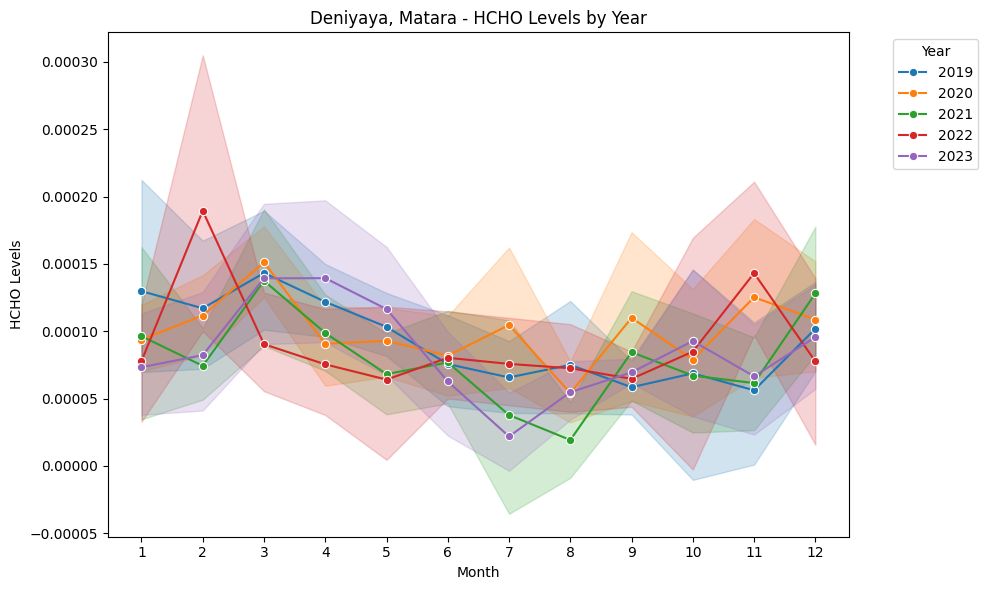

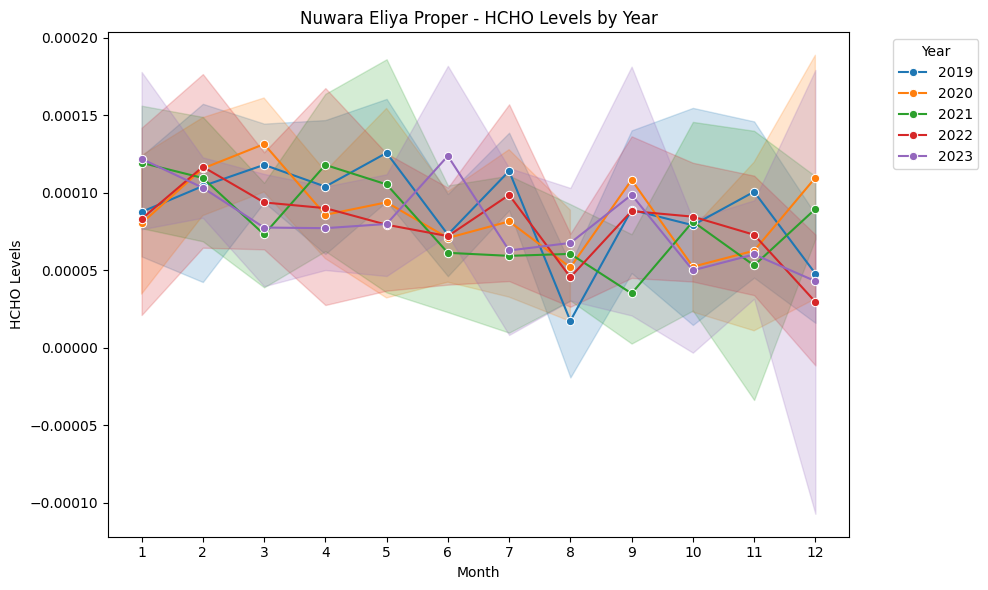

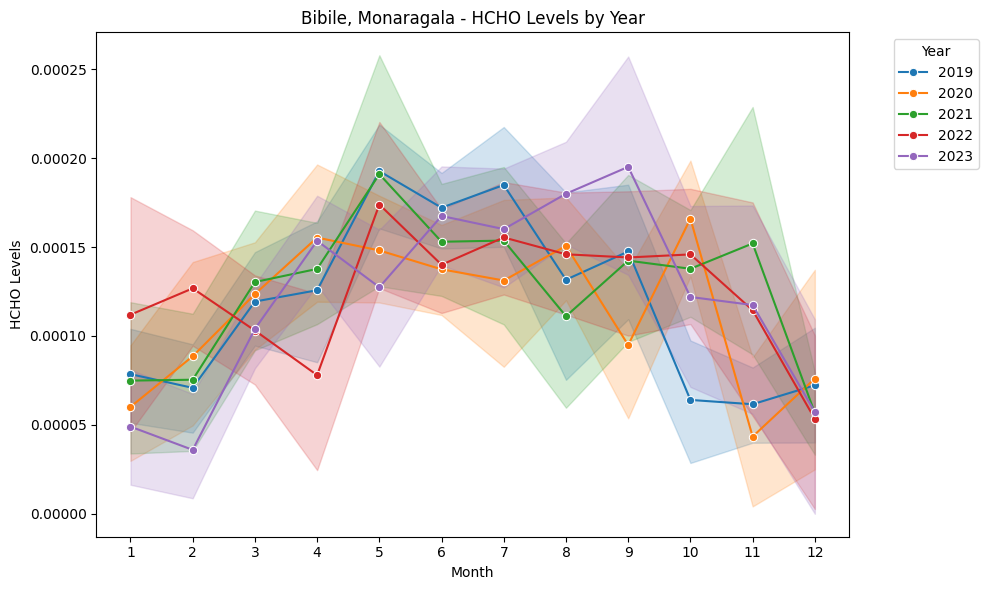

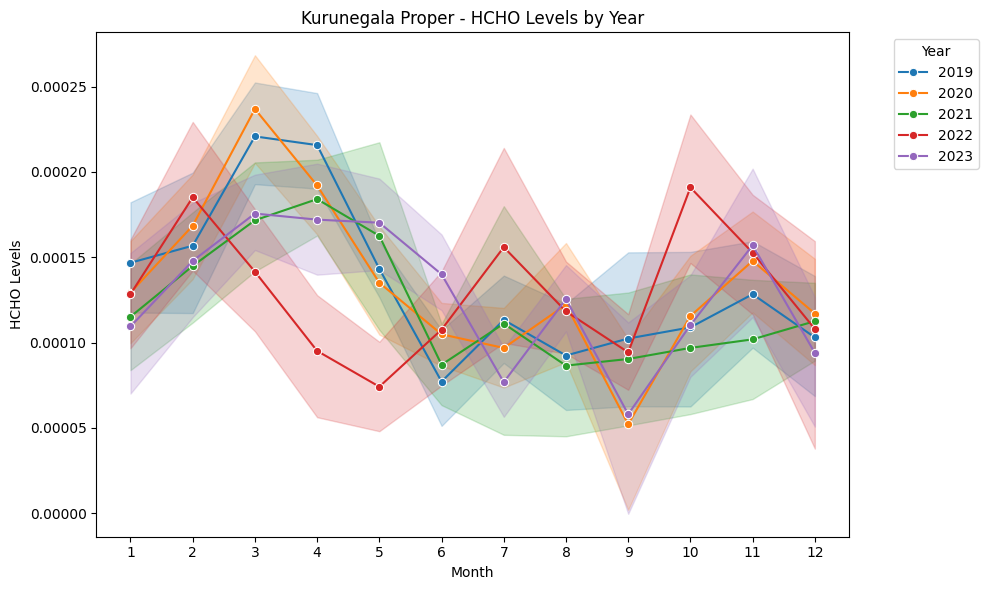

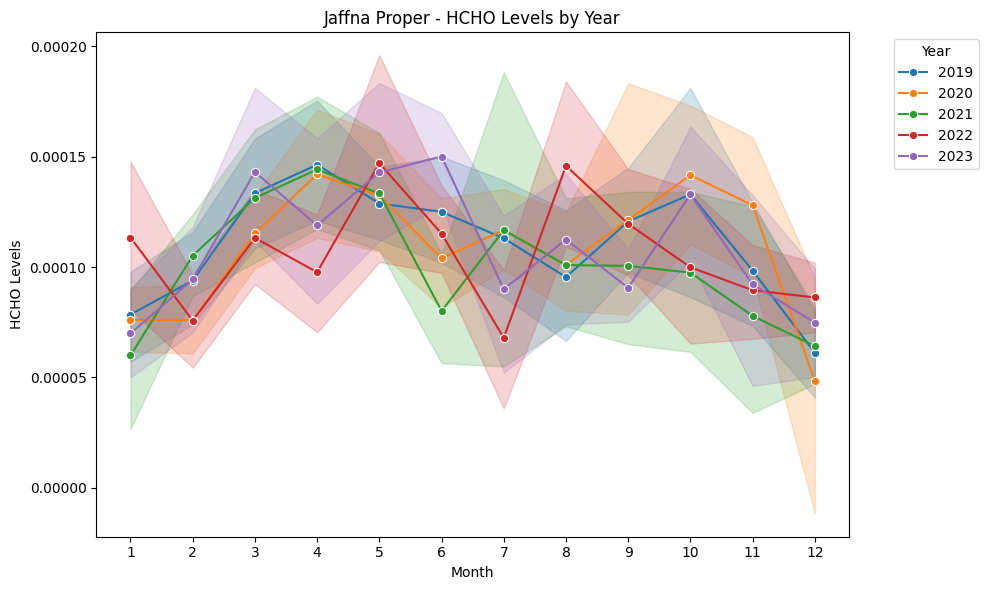

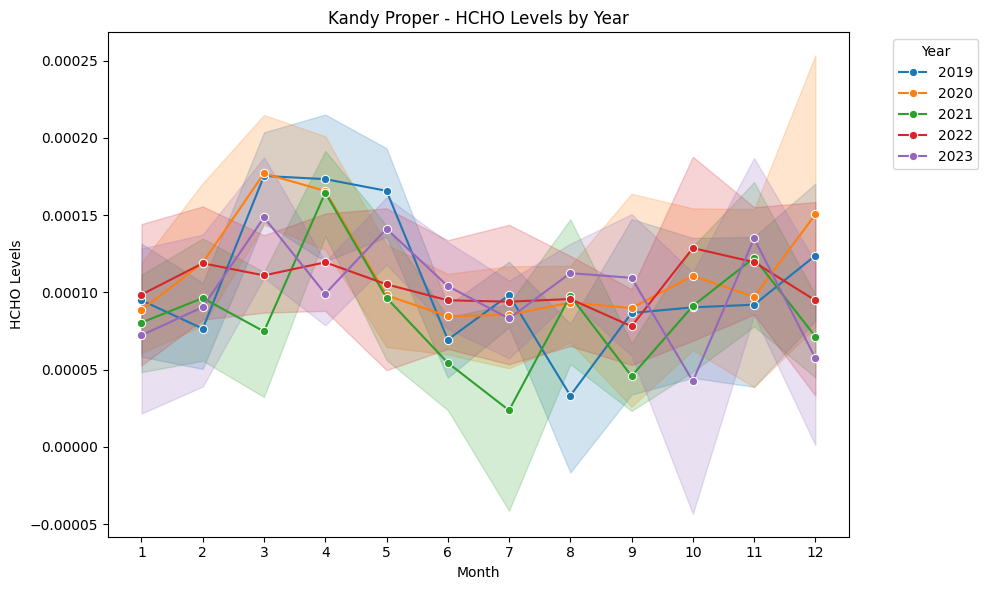

In [82]:
# Convert "Date" column to datetime format
data['Date'] = pd.to_datetime(data['Date'])

data['Month'] = data['Date'].dt.month

# Plotting using seaborn
cities = data['Location'].unique()

# Loop through each city
for city in cities:
    city_data = data[data['Location'] == city]
    years = city_data['Date'].dt.year.unique()

    plt.figure(figsize=(10, 6))
    plt.title(f'{city} - HCHO Levels by Year')
    plt.xlabel('Month')
    plt.ylabel('HCHO Levels')

    # Loop through each year
    for year in years:
        year_data = city_data[city_data['Date'].dt.year == year]
        sns.lineplot(data=year_data, x='Month', y='HCHO reading', marker='o', label=year)

    plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xticks(range(1, 13))  # Set x-axis ticks for months
    plt.tight_layout()
    plt.show()

<ipython-input-83-65feddc508b4>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lockdown_data['Date'] = pd.to_datetime(lockdown_data['Date'])
<ipython-input-83-65feddc508b4>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lockdown_data['Month'] = lockdown_data['Date'].dt.month


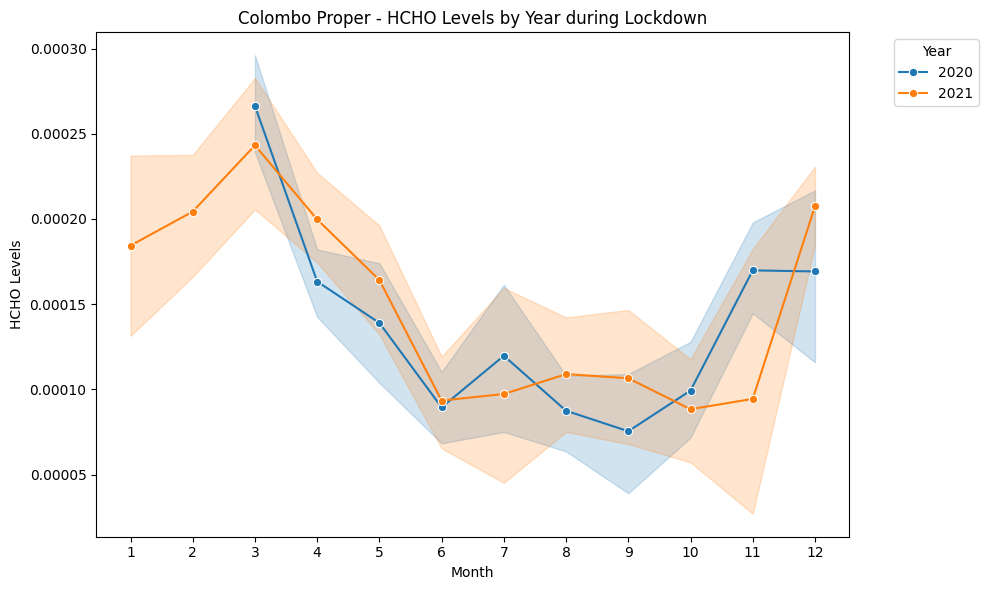

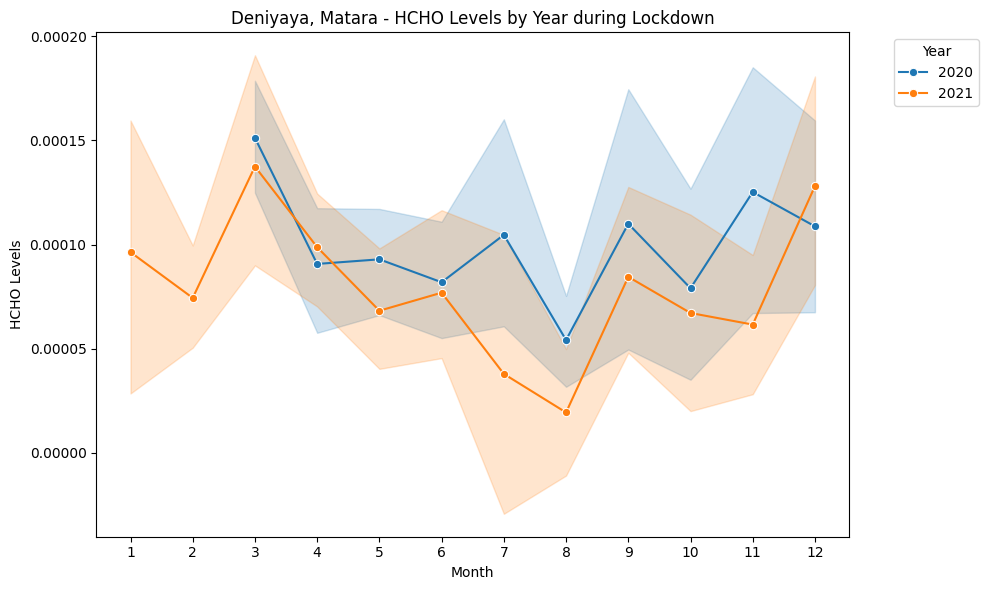

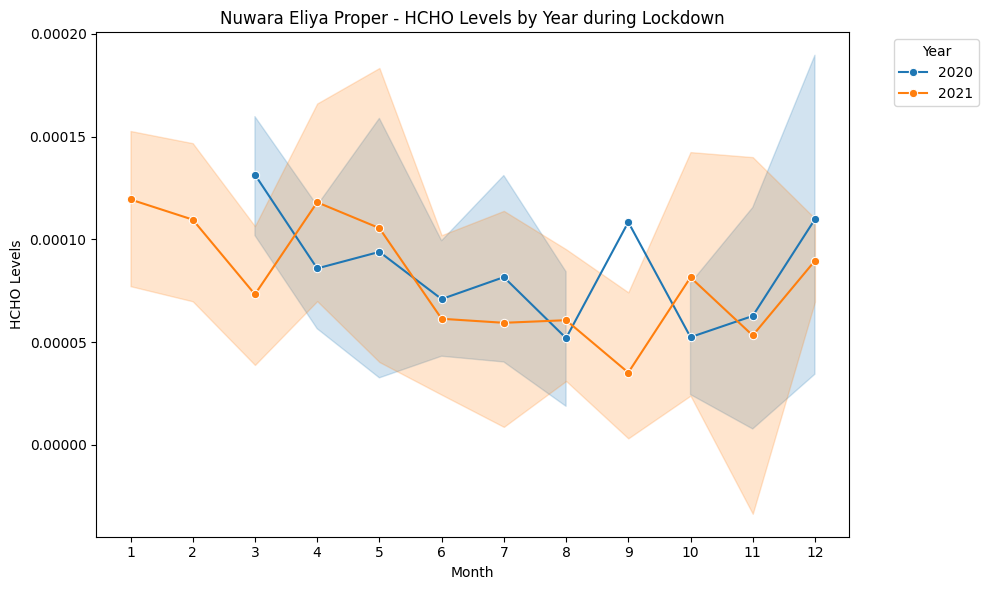

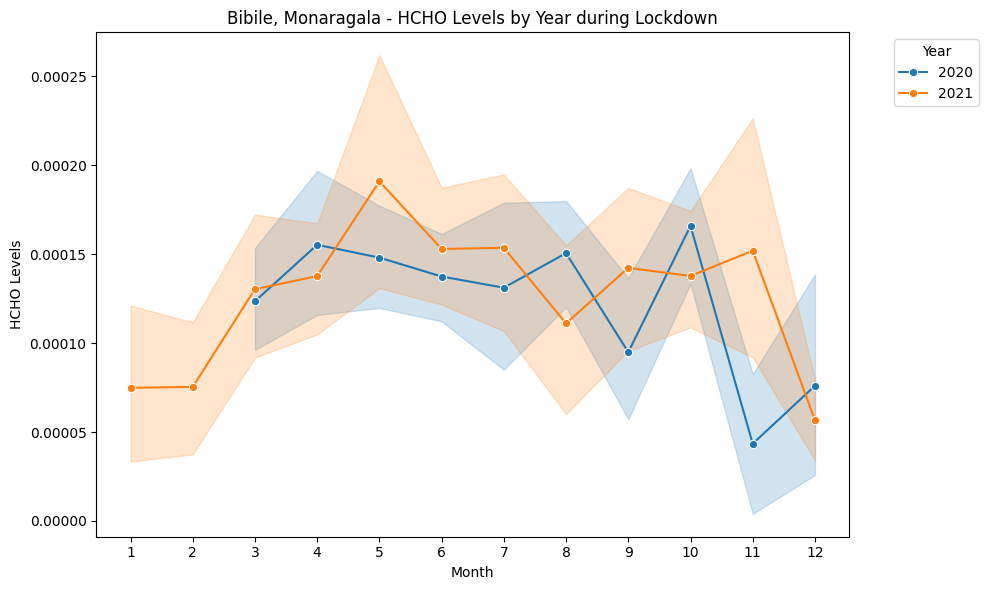

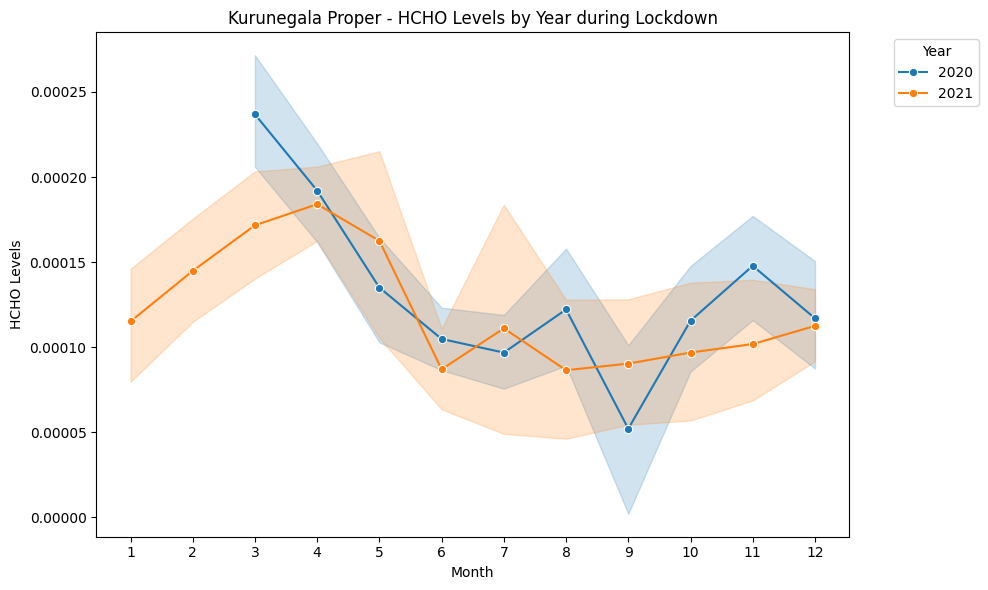

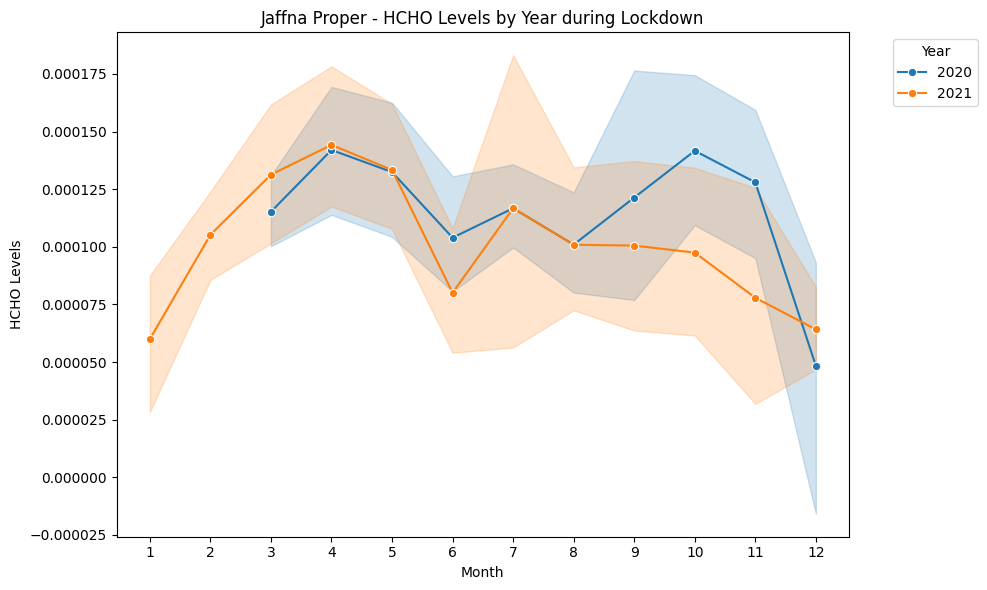

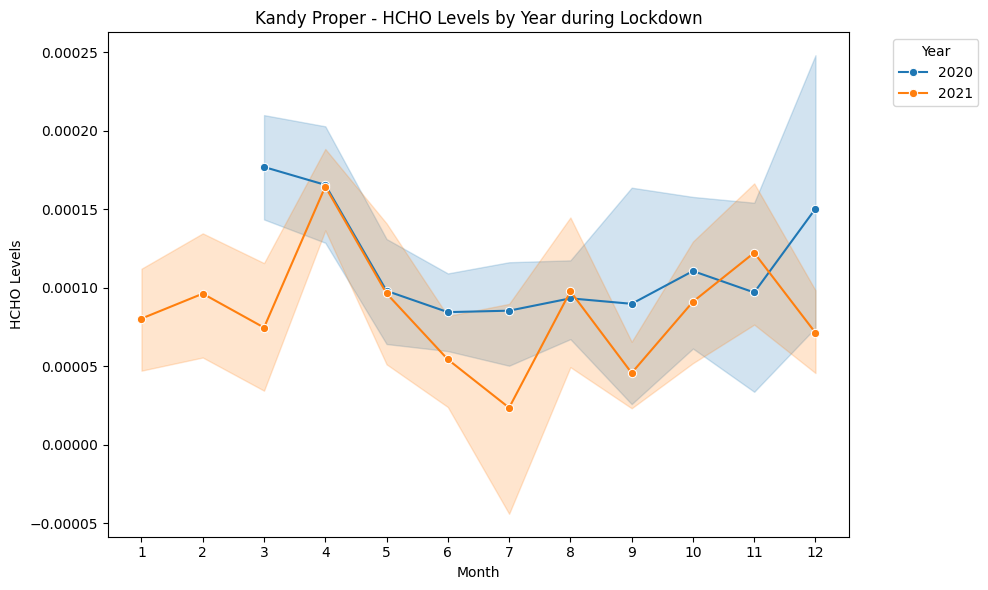

In [83]:
# Filter data for the time period from March 2020 to December 2021
lockdown_start_date = pd.to_datetime("2020-03-01")
lockdown_end_date = pd.to_datetime("2021-12-31")
lockdown_data = data[(data['Date'] >= lockdown_start_date) & (data['Date'] <= lockdown_end_date)]

# Convert "Date" column to datetime format
lockdown_data['Date'] = pd.to_datetime(lockdown_data['Date'])
lockdown_data['Month'] = lockdown_data['Date'].dt.month

# Plotting using seaborn
cities = lockdown_data['Location'].unique()

# Loop through each city
for city in cities:
    city_data = lockdown_data[lockdown_data['Location'] == city]
    years = city_data['Date'].dt.year.unique()

    plt.figure(figsize=(10, 6))
    plt.title(f'{city} - HCHO Levels by Year during Lockdown')
    plt.xlabel('Month')
    plt.ylabel('HCHO Levels')

    # Loop through each year
    for year in years:
        year_data = city_data[city_data['Date'].dt.year == year]
        sns.lineplot(data=year_data, x='Month', y='HCHO reading', marker='o', label=year)

    plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xticks(range(1, 13))  # Set x-axis ticks for months
    plt.tight_layout()
    plt.show()

In [84]:
# Descriptive statistics
summary_stats = data.groupby("Location")["HCHO reading"].describe()
print(summary_stats)

                      count      mean       std       min       25%       50%  \
Location                                                                        
Bibile, Monaragala   1131.0  0.000126  0.000094 -0.000239  0.000069  0.000125   
Colombo Proper       1339.0  0.000159  0.000099 -0.000229  0.000093  0.000151   
Deniyaya, Matara      979.0  0.000092  0.000097 -0.000259  0.000037  0.000081   
Jaffna Proper        1461.0  0.000109  0.000078 -0.000352  0.000063  0.000102   
Kandy Proper         1033.0  0.000106  0.000092 -0.000300  0.000050  0.000106   
Kurunegala Proper    1234.0  0.000134  0.000087 -0.000157  0.000078  0.000127   
Nuwara Eliya Proper   741.0  0.000088  0.000084 -0.000179  0.000034  0.000082   

                          75%       max  
Location                                 
Bibile, Monaragala   0.000185  0.000535  
Colombo Proper       0.000221  0.000650  
Deniyaya, Matara     0.000139  0.000900  
Jaffna Proper        0.000146  0.000584  
Kandy Proper      

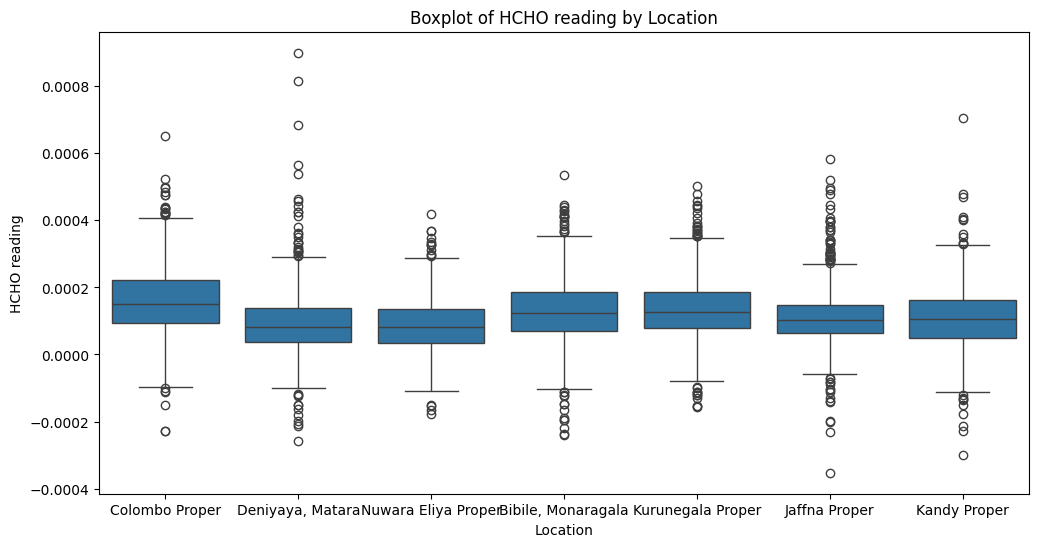

In [85]:
# Boxplots by location
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='Location', y='HCHO reading')
plt.title('Boxplot of HCHO reading by Location')
plt.xlabel('Location')
plt.ylabel('HCHO reading')
plt.show()

In [86]:
# Check for missing values in "HCHO reading" column
print("Number of missing values:", data["HCHO reading"].isnull().sum())
print(data.head())

Number of missing values: 4864
   HCHO reading        Location Current Date  Year       Date  Month
0      0.000197  Colombo Proper   2019-01-01  2019 2019-01-01      1
1      0.000263  Colombo Proper   2019-01-02  2019 2019-01-02      1
2      0.000099  Colombo Proper   2019-01-03  2019 2019-01-03      1
3      0.000210  Colombo Proper   2019-01-04  2019 2019-01-04      1
4      0.000179  Colombo Proper   2019-01-05  2019 2019-01-05      1


In [87]:
# Remove rows with missing values
data_cleaned = data.dropna(subset=["HCHO reading"])

In [88]:
# Remove outliers using IQR method
Q1 = data_cleaned["HCHO reading"].quantile(0.25)
Q3 = data_cleaned["HCHO reading"].quantile(0.75)
IQR = Q3 - Q1

# Define upper and lower bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter data based on bounds
data_cleaned = data_cleaned[(data_cleaned["HCHO reading"] >= lower_bound) & (data_cleaned["HCHO reading"] <= upper_bound)]

# Check the shape of the cleaned data
print("Shape of original data:", data.shape)
print("Shape of cleaned data:", data_cleaned.shape)

Shape of original data: (12782, 6)
Shape of cleaned data: (7703, 6)


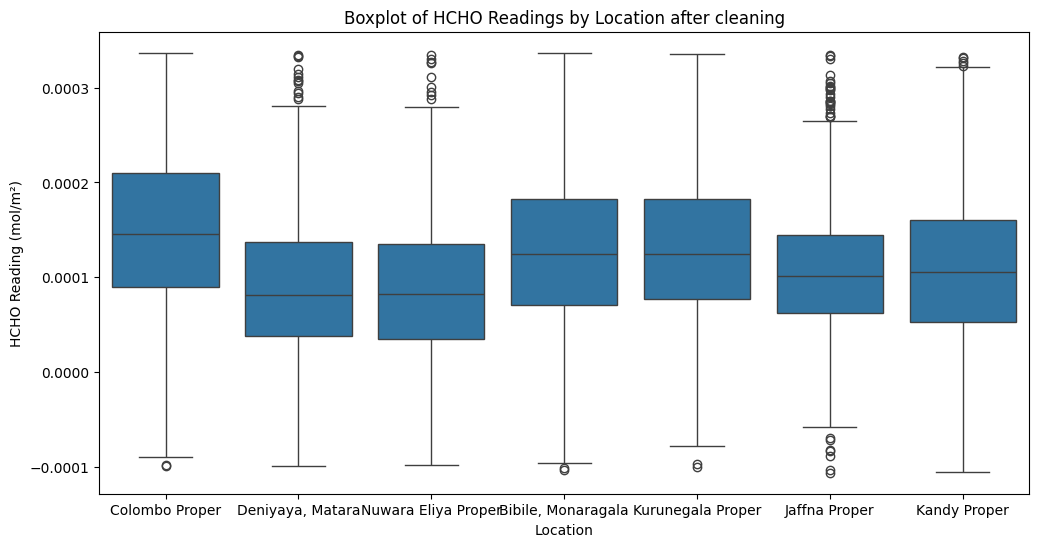

In [89]:
# Boxplots for each location
plt.figure(figsize=(12, 6))
sns.boxplot(data=data_cleaned, x='Location', y='HCHO reading')
plt.title('Boxplot of HCHO Readings by Location after cleaning')
plt.xlabel('Location')
plt.ylabel('HCHO Reading (mol/m²)')
plt.show()

In [90]:
# Remove duplicate rows
data_cleaned = data_cleaned.drop_duplicates()

# Standardize location names (e.g., convert to lowercase)
data_cleaned["Location"] = data_cleaned["Location"].str.lower()

In [91]:
print(data_cleaned.head())

   HCHO reading        Location Current Date  Year       Date  Month
0      0.000197  colombo proper   2019-01-01  2019 2019-01-01      1
1      0.000263  colombo proper   2019-01-02  2019 2019-01-02      1
2      0.000099  colombo proper   2019-01-03  2019 2019-01-03      1
3      0.000210  colombo proper   2019-01-04  2019 2019-01-04      1
4      0.000179  colombo proper   2019-01-05  2019 2019-01-05      1


In [92]:
# Descriptive statistics
summary_stats = data_cleaned.groupby("Location")["HCHO reading"].describe()
print(summary_stats)

                      count      mean       std       min       25%       50%  \
Location                                                                        
bibile, monaragala   1098.0  0.000125  0.000081 -0.000103  0.000071  0.000124   
colombo proper       1273.0  0.000149  0.000084 -0.000099  0.000090  0.000146   
deniyaya, matara      953.0  0.000088  0.000076 -0.000099  0.000038  0.000081   
jaffna proper        1433.0  0.000106  0.000066 -0.000106  0.000063  0.000101   
kandy proper         1014.0  0.000107  0.000082 -0.000105  0.000053  0.000106   
kurunegala proper    1200.0  0.000131  0.000076 -0.000100  0.000078  0.000125   
nuwara eliya proper   732.0  0.000088  0.000079 -0.000098  0.000035  0.000082   

                          75%       max  
Location                                 
bibile, monaragala   0.000183  0.000336  
colombo proper       0.000210  0.000337  
deniyaya, matara     0.000137  0.000334  
jaffna proper        0.000145  0.000334  
kandy proper      

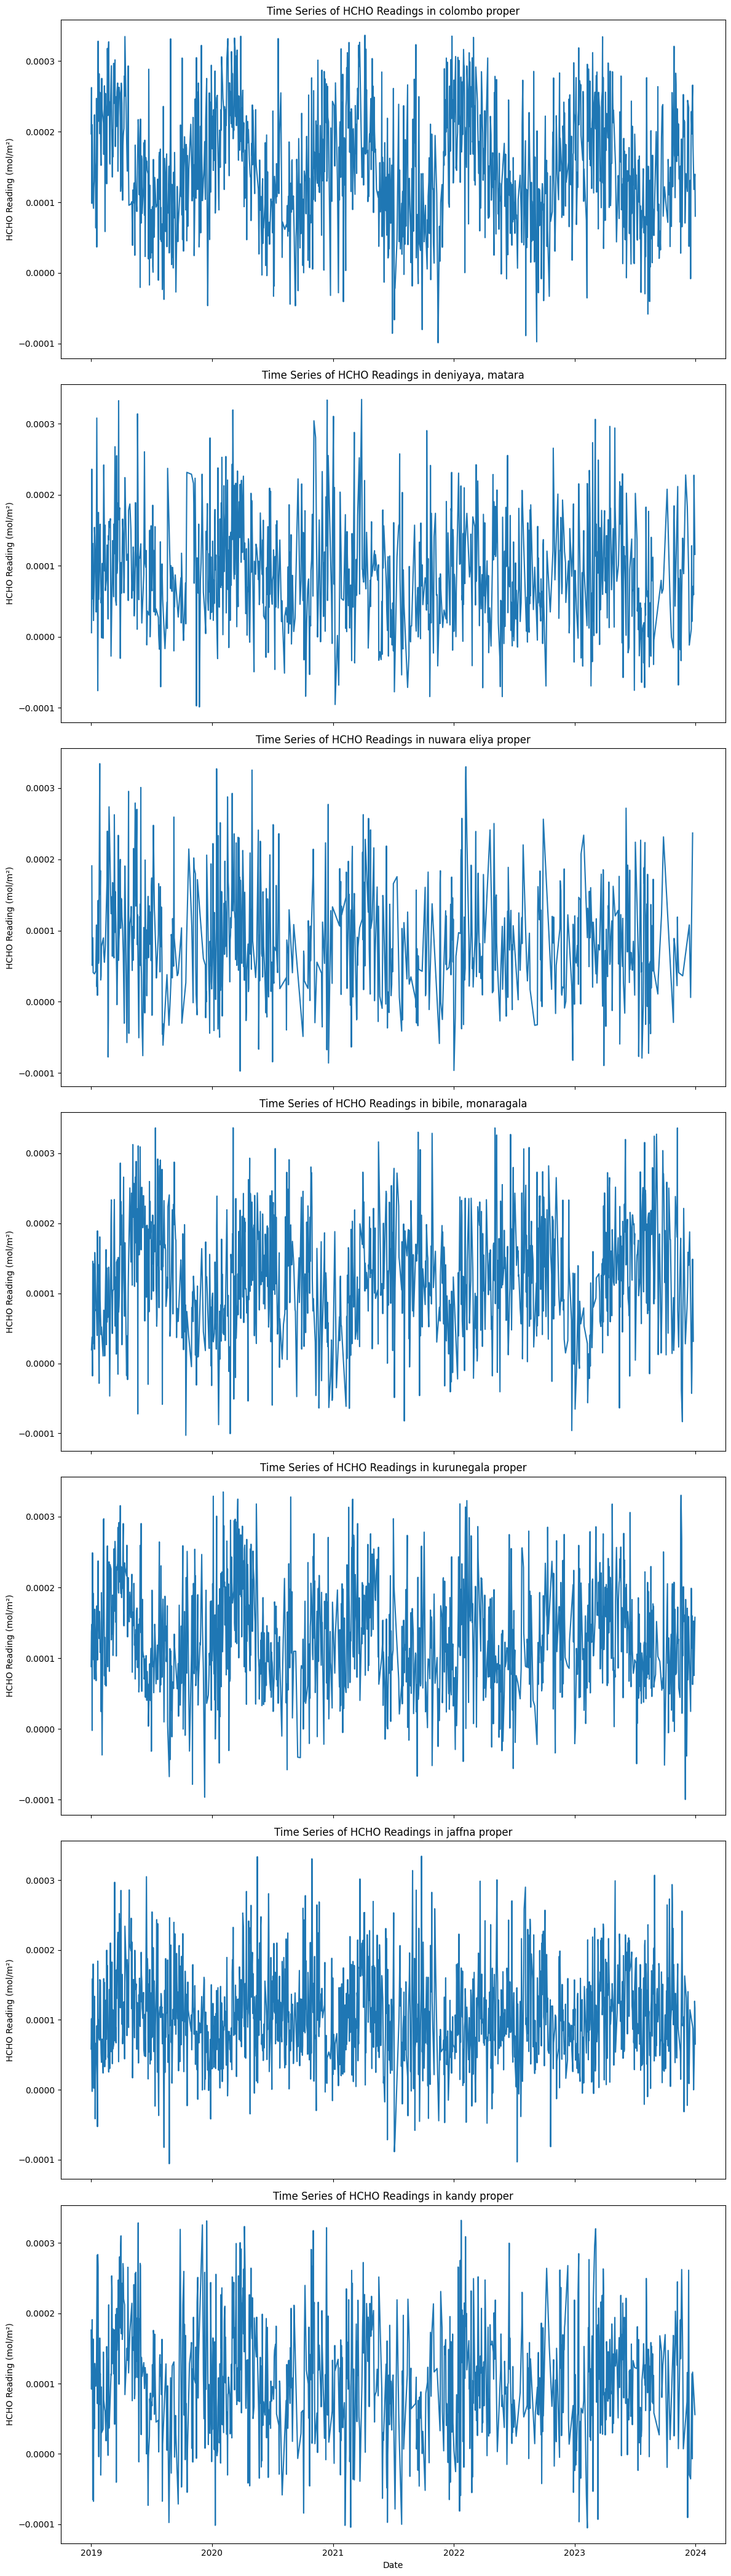

In [93]:
# Convert 'Current Date' to datetime format
data_cleaned['Current Date'] = pd.to_datetime(data_cleaned['Current Date'])

# Create subplots for each city
cities = data_cleaned['Location'].unique()
num_cities = len(cities)
fig, axes = plt.subplots(num_cities, 1, figsize=(12, 6*num_cities), sharex=True)

# Plot time series graphs for each city
for i, city in enumerate(cities):
    sns.lineplot(ax=axes[i], data=data_cleaned[data_cleaned['Location'] == city], x='Current Date', y='HCHO reading')
    axes[i].set_title(f'Time Series of HCHO Readings in {city}')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('HCHO Reading (mol/m²)')

plt.tight_layout()
plt.show()

SPATIO-TEMPORAL ANALYSIS

In [94]:
# Load weather data for Colombo
colombo_weather = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/ColomboDailyPrecipTempDataCSV.csv", header=0, names=["Station", "Location", "Date", "PRCP", "TEMPAVG", "TEMPMAX", "TEMPMIN"])

# Load weather data for Kurunegala
kurunegala_weather = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/KurunegalaDailyPrecipTempDataCSV.csv", header=0, names=["Station", "Location", "Date", "PRCP", "TEMPAVG", "TEMPMAX", "TEMPMIN"])

# Load weather data for Nuwara Eliya
nuwara_eliya_weather = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/NuwaraEliyaDailyPrecipTempCSV.csv", header=0, names=["Station", "Location", "Date", "PRCP", "TEMPAVG", "TEMPMAX", "TEMPMIN"])

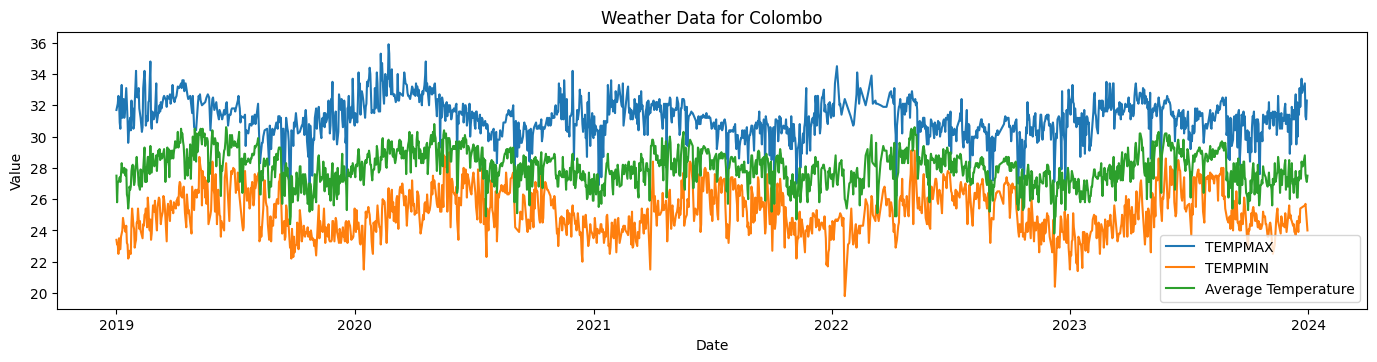

In [95]:
# Convert 'Date' to datetime format
colombo_weather['Date'] = pd.to_datetime(colombo_weather['Date'])
kurunegala_weather['Date'] = pd.to_datetime(kurunegala_weather['Date'])
nuwara_eliya_weather['Date'] = pd.to_datetime(nuwara_eliya_weather['Date'])

plt.figure(figsize=(14, 10))

# Plot for Colombo
plt.subplot(3, 1, 1)
sns.lineplot(data=colombo_weather, x='Date', y='TEMPMAX', label='TEMPMAX')
sns.lineplot(data=colombo_weather, x='Date', y='TEMPMIN', label='TEMPMIN')
sns.lineplot(data=colombo_weather, x='Date', y='TEMPAVG', label='Average Temperature')
plt.title('Weather Data for Colombo')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()

plt.tight_layout()
plt.show()

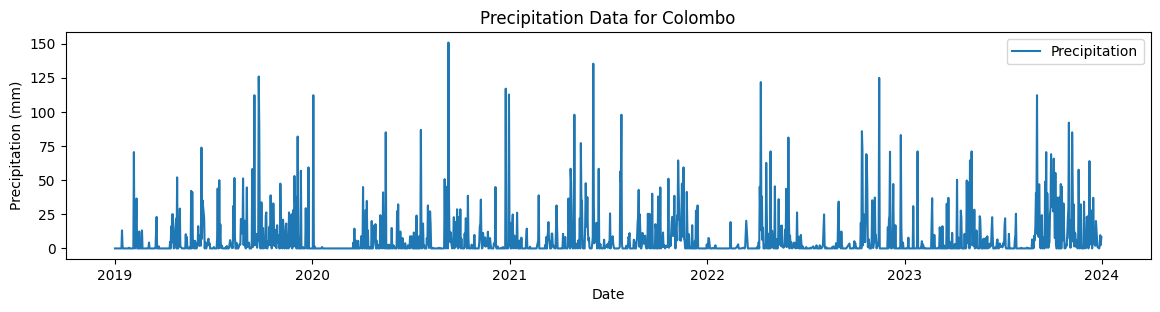

In [96]:
# Plot for Colombo
plt.figure(figsize=(14, 10))
plt.subplot(3, 1, 1)
sns.lineplot(data=colombo_weather, x='Date', y='PRCP', label='Precipitation')
plt.title('Precipitation Data for Colombo')
plt.xlabel('Date')
plt.ylabel('Precipitation (mm)')
plt.legend()

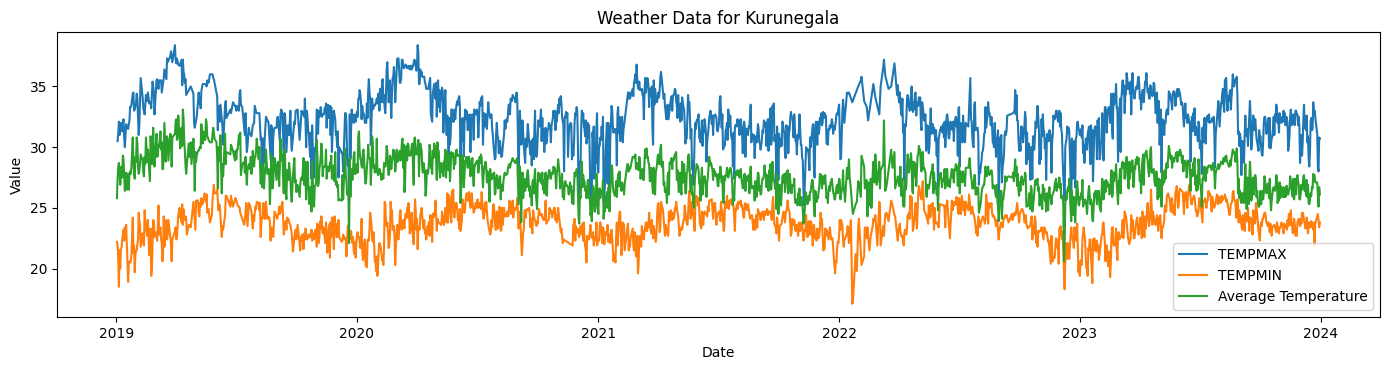

In [97]:
# Plot for Kurunegala
plt.figure(figsize=(14, 10))

plt.subplot(3, 1, 2)
sns.lineplot(data=kurunegala_weather, x='Date', y='TEMPMAX', label='TEMPMAX')
sns.lineplot(data=kurunegala_weather, x='Date', y='TEMPMIN', label='TEMPMIN')
sns.lineplot(data=kurunegala_weather, x='Date', y='TEMPAVG', label='Average Temperature')
plt.title('Weather Data for Kurunegala')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()

plt.tight_layout()
plt.show()

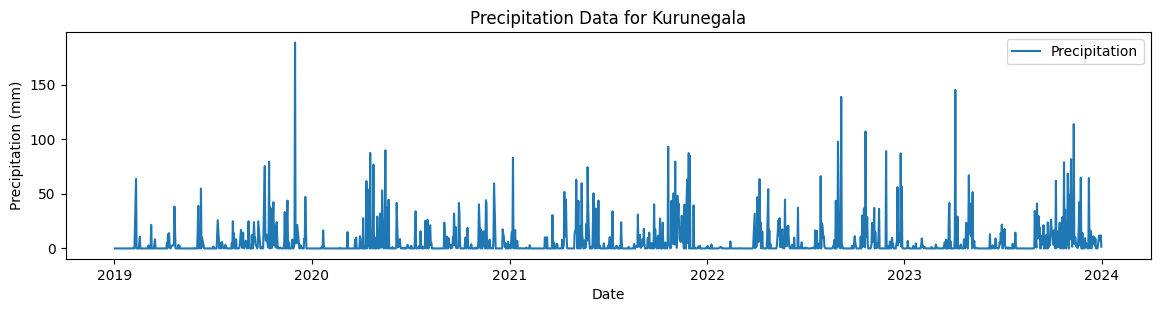

In [98]:
# Plot for Kurunegala
plt.figure(figsize=(14, 10))
plt.subplot(3, 1, 2)
sns.lineplot(data=kurunegala_weather, x='Date', y='PRCP', label='Precipitation')
plt.title('Precipitation Data for Kurunegala')
plt.xlabel('Date')
plt.ylabel('Precipitation (mm)')
plt.legend()

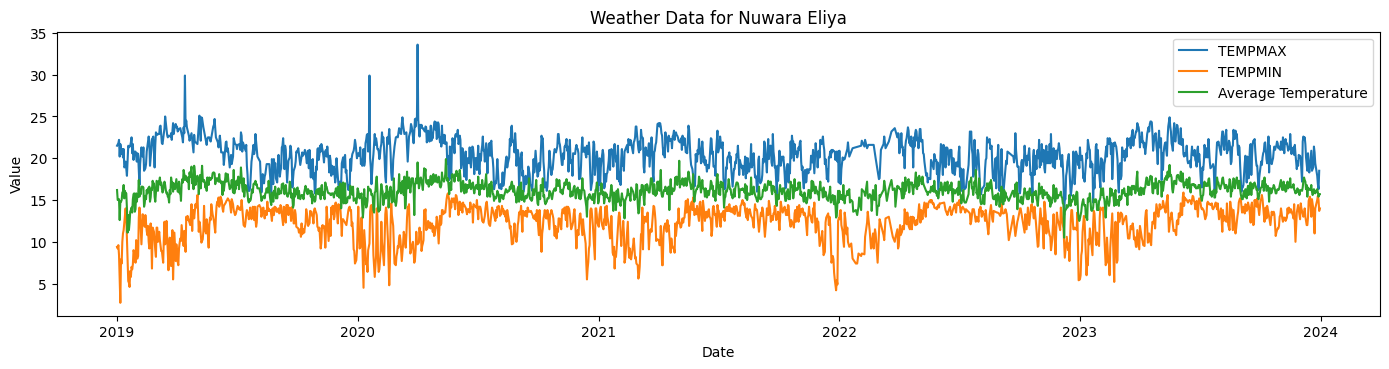

In [99]:
# Plot for Nuwara Eliya
plt.figure(figsize=(14, 10))

plt.subplot(3, 1, 3)
sns.lineplot(data=nuwara_eliya_weather, x='Date', y='TEMPMAX', label='TEMPMAX')
sns.lineplot(data=nuwara_eliya_weather, x='Date', y='TEMPMIN', label='TEMPMIN')
sns.lineplot(data=nuwara_eliya_weather, x='Date', y='TEMPAVG', label='Average Temperature')
plt.title('Weather Data for Nuwara Eliya')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()

plt.tight_layout()
plt.show()

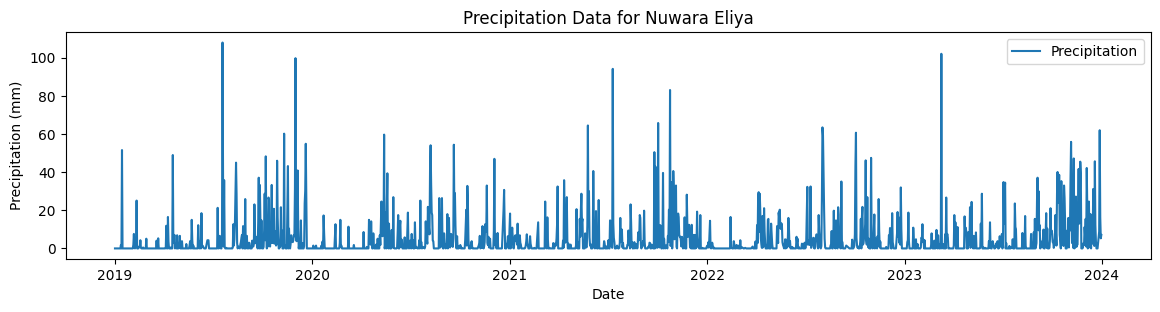

In [100]:
# Plot for Nuwara Eliya
plt.figure(figsize=(14, 10))
plt.subplot(3, 1, 3)
sns.lineplot(data=nuwara_eliya_weather, x='Date', y='PRCP', label='Precipitation')
plt.title('Precipitation Data for Nuwara Eliya')
plt.xlabel('Date')
plt.ylabel('Precipitation (mm)')
plt.legend()

In [101]:
print(colombo_weather.head())
print("Shape of original data:", colombo_weather.shape)

       Station     Location       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN
0  CEM00043466  COLOMBO, CE 2019-01-01   0.0     27.5     31.7     23.4
1  CEM00043466  COLOMBO, CE 2019-01-02   0.0     25.8      NaN     23.1
2  CEM00043466  COLOMBO, CE 2019-01-03   0.0     27.1     32.1     23.1
3  CEM00043466  COLOMBO, CE 2019-01-04   0.0     27.1     32.6     22.5
4  CEM00043466  COLOMBO, CE 2019-01-05   0.0     27.2     32.3     23.5
Shape of original data: (1765, 7)


In [102]:
print(kurunegala_weather.head())
print("Shape of original data:", kurunegala_weather.shape)

       Station        Location       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN
0  CEM00043441  KURUNEGALA, CE 2019-01-02   0.0     25.8      NaN     22.2
1  CEM00043441  KURUNEGALA, CE 2019-01-03   0.0     27.4     30.5     21.9
2  CEM00043441  KURUNEGALA, CE 2019-01-04   0.0     28.4     31.1     20.8
3  CEM00043441  KURUNEGALA, CE 2019-01-05   0.0     28.7     32.1     18.5
4  CEM00043441  KURUNEGALA, CE 2019-01-06   0.0     28.0     31.0     21.5
Shape of original data: (1704, 7)


In [103]:
print(nuwara_eliya_weather.head())
print("Shape of original data:", nuwara_eliya_weather.shape)

       Station          Location       Date  PRCP  TEMPAVG  TEMPMAX  TEMPMIN
0  CE000434730  NUWARA ELIYA, CE 2019-01-01   0.0     16.2     21.5      9.4
1  CE000434730  NUWARA ELIYA, CE 2019-01-02   0.0     15.0      NaN      9.2
2  CE000434730  NUWARA ELIYA, CE 2019-01-03   0.0     15.1     21.8      9.6
3  CE000434730  NUWARA ELIYA, CE 2019-01-04   0.0     15.1     22.2      8.4
4  CE000434730  NUWARA ELIYA, CE 2019-01-05   0.0     12.6     20.2      NaN
Shape of original data: (1761, 7)


In [104]:
columns_to_remove = ['Station', 'TEMPMAX', 'TEMPMIN']
colombo_weather.drop(columns=columns_to_remove, inplace=True)
kurunegala_weather.drop(columns=columns_to_remove, inplace=True)
nuwara_eliya_weather.drop(columns=columns_to_remove, inplace=True)

In [105]:
# Handle missing values
colombo_weather.dropna(inplace=True)
kurunegala_weather.dropna(inplace=True)
nuwara_eliya_weather.dropna(inplace=True)

In [106]:
# Convert date columns to datetime format
colombo_weather['Date'] = pd.to_datetime(colombo_weather['Date'])
kurunegala_weather['Date'] = pd.to_datetime(kurunegala_weather['Date'])
nuwara_eliya_weather['Date'] = pd.to_datetime(nuwara_eliya_weather['Date'])

In [107]:
# Check for duplicates
print("Duplicates in Colombo weather data:", colombo_weather.duplicated().sum())
print("Duplicates in Kurunegala weather data:", kurunegala_weather.duplicated().sum())
print("Duplicates in Nuwara Eliya weather data:", nuwara_eliya_weather.duplicated().sum())

Duplicates in Colombo weather data: 0
Duplicates in Kurunegala weather data: 0
Duplicates in Nuwara Eliya weather data: 0


In [108]:
colombo_weather["Location"] = colombo_weather["Location"].str.lower()
kurunegala_weather["Location"] = kurunegala_weather["Location"].str.lower()
nuwara_eliya_weather["Location"] = nuwara_eliya_weather["Location"].str.lower()

In [109]:
print(colombo_weather.head())
print(kurunegala_weather.head())
print(nuwara_eliya_weather.head())

      Location       Date  PRCP  TEMPAVG
0  colombo, ce 2019-01-01   0.0     27.5
1  colombo, ce 2019-01-02   0.0     25.8
2  colombo, ce 2019-01-03   0.0     27.1
3  colombo, ce 2019-01-04   0.0     27.1
4  colombo, ce 2019-01-05   0.0     27.2
         Location       Date  PRCP  TEMPAVG
0  kurunegala, ce 2019-01-02   0.0     25.8
1  kurunegala, ce 2019-01-03   0.0     27.4
2  kurunegala, ce 2019-01-04   0.0     28.4
3  kurunegala, ce 2019-01-05   0.0     28.7
4  kurunegala, ce 2019-01-06   0.0     28.0
           Location       Date  PRCP  TEMPAVG
0  nuwara eliya, ce 2019-01-01   0.0     16.2
1  nuwara eliya, ce 2019-01-02   0.0     15.0
2  nuwara eliya, ce 2019-01-03   0.0     15.1
3  nuwara eliya, ce 2019-01-04   0.0     15.1
4  nuwara eliya, ce 2019-01-05   0.0     12.6


In [110]:
location_mapping = {
    "colombo proper": "colombo, ce",
    "kurunegala proper": "kurunegala, ce",
    "nuwara eliya proper": "nuwara eliya, ce"
}

data_cleaned['Location'] = data_cleaned['Location'].map(location_mapping)

In [111]:
# Merge weather data with HCHO dataset
merged_colombo = pd.merge(data_cleaned[data_cleaned["Location"] == "colombo, ce"], colombo_weather, left_on="Current Date", right_on="Date", how="left")
merged_kurunegala = pd.merge(data_cleaned[data_cleaned["Location"] == "kurunegala, ce"], kurunegala_weather, left_on="Current Date", right_on="Date", how="left")
merged_nuwara_eliya = pd.merge(data_cleaned[data_cleaned["Location"] == "nuwara eliya, ce"], nuwara_eliya_weather, left_on="Current Date", right_on="Date", how="left")

In [112]:
print("COLOMBO")
print(merged_colombo.head())

COLOMBO
   HCHO reading   Location_x Current Date  Year     Date_x  Month  \
0      0.000197  colombo, ce   2019-01-01  2019 2019-01-01      1   
1      0.000263  colombo, ce   2019-01-02  2019 2019-01-02      1   
2      0.000099  colombo, ce   2019-01-03  2019 2019-01-03      1   
3      0.000210  colombo, ce   2019-01-04  2019 2019-01-04      1   
4      0.000179  colombo, ce   2019-01-05  2019 2019-01-05      1   

    Location_y     Date_y  PRCP  TEMPAVG  
0  colombo, ce 2019-01-01   0.0     27.5  
1  colombo, ce 2019-01-02   0.0     25.8  
2  colombo, ce 2019-01-03   0.0     27.1  
3  colombo, ce 2019-01-04   0.0     27.1  
4  colombo, ce 2019-01-05   0.0     27.2  


In [113]:
print("\nKURUNEGALA")
print(merged_kurunegala.head())


KURUNEGALA
   HCHO reading      Location_x Current Date  Year     Date_x  Month  \
0      0.000088  kurunegala, ce   2019-01-01  2019 2019-01-01      1   
1      0.000137  kurunegala, ce   2019-01-02  2019 2019-01-02      1   
2      0.000148  kurunegala, ce   2019-01-03  2019 2019-01-03      1   
3     -0.000002  kurunegala, ce   2019-01-04  2019 2019-01-04      1   
4      0.000249  kurunegala, ce   2019-01-05  2019 2019-01-05      1   

       Location_y     Date_y  PRCP  TEMPAVG  
0             NaN        NaT   NaN      NaN  
1  kurunegala, ce 2019-01-02   0.0     25.8  
2  kurunegala, ce 2019-01-03   0.0     27.4  
3  kurunegala, ce 2019-01-04   0.0     28.4  
4  kurunegala, ce 2019-01-05   0.0     28.7  


In [114]:
print("\nNUWARA")
print(merged_nuwara_eliya.head())


NUWARA
   HCHO reading        Location_x Current Date  Year     Date_x  Month  \
0      0.000191  nuwara eliya, ce   2019-01-03  2019 2019-01-03      1   
1      0.000051  nuwara eliya, ce   2019-01-04  2019 2019-01-04      1   
2      0.000065  nuwara eliya, ce   2019-01-05  2019 2019-01-05      1   
3      0.000090  nuwara eliya, ce   2019-01-06  2019 2019-01-06      1   
4      0.000041  nuwara eliya, ce   2019-01-07  2019 2019-01-07      1   

         Location_y     Date_y  PRCP  TEMPAVG  
0  nuwara eliya, ce 2019-01-03   0.0     15.1  
1  nuwara eliya, ce 2019-01-04   0.0     15.1  
2  nuwara eliya, ce 2019-01-05   0.0     12.6  
3  nuwara eliya, ce 2019-01-06   0.0     14.8  
4  nuwara eliya, ce 2019-01-07   0.0     14.8  


In [115]:
columns_to_remove = ['Location_y', 'Current Date', 'Date_y', 'Year']
merged_colombo.drop(columns=columns_to_remove, inplace=True)
merged_kurunegala.drop(columns=columns_to_remove, inplace=True)
merged_nuwara_eliya.drop(columns=columns_to_remove, inplace=True)

merged_colombo.rename(columns={'Location_x': 'Location', 'Date_x': 'Date'}, inplace=True)
merged_kurunegala.rename(columns={'Location_x': 'Location', 'Date_x': 'Date'}, inplace=True)
merged_nuwara_eliya.rename(columns={'Location_x': 'Location', 'Date_x': 'Date'}, inplace=True)


In [116]:
# Handle missing values
merged_colombo.dropna(inplace=True)
merged_kurunegala.dropna(inplace=True)
merged_nuwara_eliya.dropna(inplace=True)

In [117]:
print("COLOMBO")
print(merged_colombo.head())
print("\nKURUNEGALA")
print(merged_kurunegala.head())
print("\nNUWARA")
print(merged_nuwara_eliya.head())

COLOMBO
   HCHO reading     Location       Date  Month  PRCP  TEMPAVG
0      0.000197  colombo, ce 2019-01-01      1   0.0     27.5
1      0.000263  colombo, ce 2019-01-02      1   0.0     25.8
2      0.000099  colombo, ce 2019-01-03      1   0.0     27.1
3      0.000210  colombo, ce 2019-01-04      1   0.0     27.1
4      0.000179  colombo, ce 2019-01-05      1   0.0     27.2

KURUNEGALA
   HCHO reading        Location       Date  Month  PRCP  TEMPAVG
1      0.000137  kurunegala, ce 2019-01-02      1   0.0     25.8
2      0.000148  kurunegala, ce 2019-01-03      1   0.0     27.4
3     -0.000002  kurunegala, ce 2019-01-04      1   0.0     28.4
4      0.000249  kurunegala, ce 2019-01-05      1   0.0     28.7
5      0.000102  kurunegala, ce 2019-01-06      1   0.0     28.0

NUWARA
   HCHO reading          Location       Date  Month  PRCP  TEMPAVG
0      0.000191  nuwara eliya, ce 2019-01-03      1   0.0     15.1
1      0.000051  nuwara eliya, ce 2019-01-04      1   0.0     15.1
2      0.

In [118]:
print("COLOMBO")
print(merged_colombo.shape)
print("\nKURUNEGALA")
print(merged_kurunegala.shape)
print("\nNUWARA")
print(merged_nuwara_eliya.shape)

COLOMBO
(1218, 6)

KURUNEGALA
(1109, 6)

NUWARA
(691, 6)


In [119]:
print("Duplicates in Colombo weather data:", merged_colombo.duplicated().sum())
print("Duplicates in Kurunegala weather data:", merged_kurunegala.duplicated().sum())
print("Duplicates in Nuwara Eliya weather data:", merged_nuwara_eliya.duplicated().sum())

Duplicates in Colombo weather data: 0
Duplicates in Kurunegala weather data: 0
Duplicates in Nuwara Eliya weather data: 0


In [120]:
merged_colombo.to_csv('merged_colombo.csv', index=False)
merged_kurunegala.to_csv('merged_kurunegala.csv', index=False)
merged_nuwara_eliya.to_csv('merged_nuwara_eliya.csv', index=False)

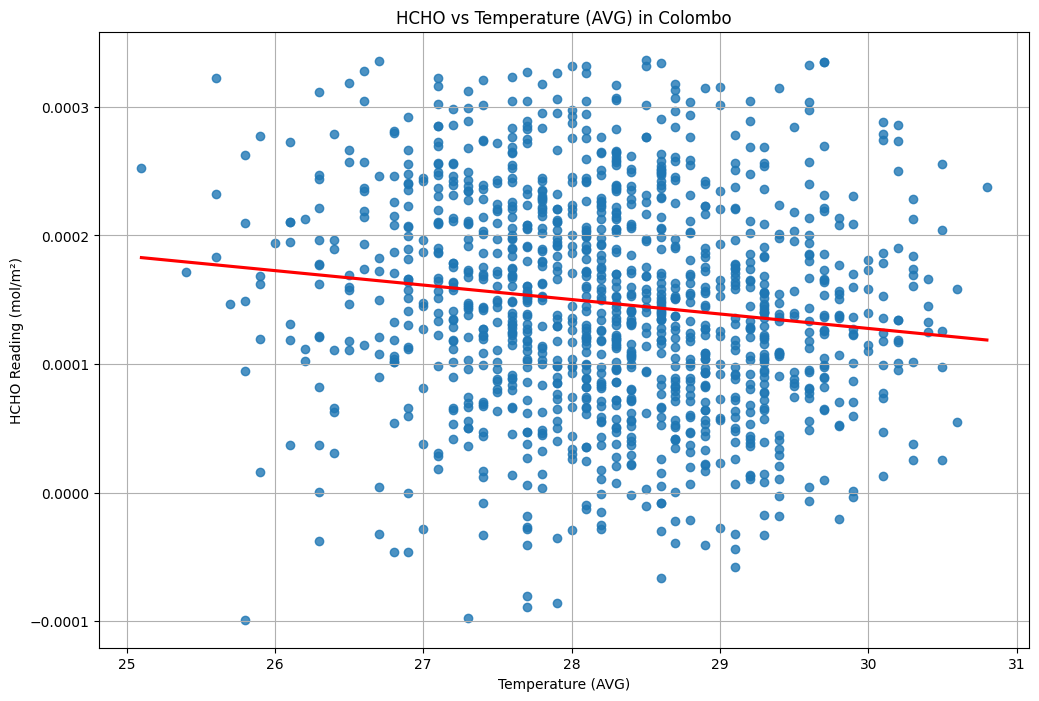

In [121]:
# Convert 'Current Date' column to datetime
merged_colombo['Date'] = pd.to_datetime(merged_colombo['Date'])
merged_kurunegala['Date'] = pd.to_datetime(merged_kurunegala['Date'])
merged_nuwara_eliya['Date'] = pd.to_datetime(merged_nuwara_eliya['Date'])

# Extract year from 'Current Date' and create a new column
merged_colombo['Year'] = merged_colombo['Date'].dt.year
merged_kurunegala['Year'] = merged_kurunegala['Date'].dt.year
merged_nuwara_eliya['Year'] = merged_nuwara_eliya['Date'].dt.year

# Plot HCHO vs TEMPAVG for each year for Colombo
plt.figure(figsize=(12, 8))
sns.regplot(data=merged_colombo, x='TEMPAVG', y='HCHO reading', scatter=True, ci=None, line_kws={"color": "red"})
plt.title('HCHO vs Temperature (AVG) in Colombo')
plt.xlabel('Temperature (AVG)')
plt.ylabel('HCHO Reading (mol/m²)')
plt.grid(True)
plt.show()

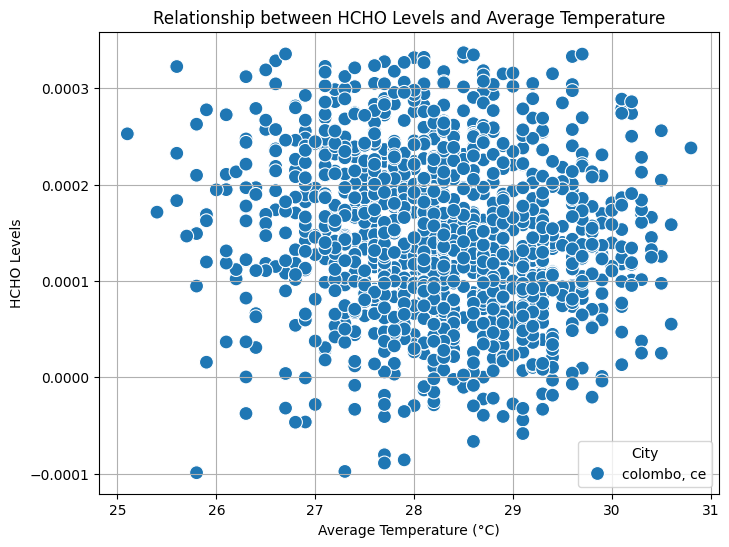

In [122]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=merged_colombo, x='TEMPAVG', y='HCHO reading', hue='Location', s=100)
plt.title('Relationship between HCHO Levels and Average Temperature')
plt.xlabel('Average Temperature (°C)')
plt.ylabel('HCHO Levels')
plt.legend(title='City')
plt.grid(True)
plt.show()

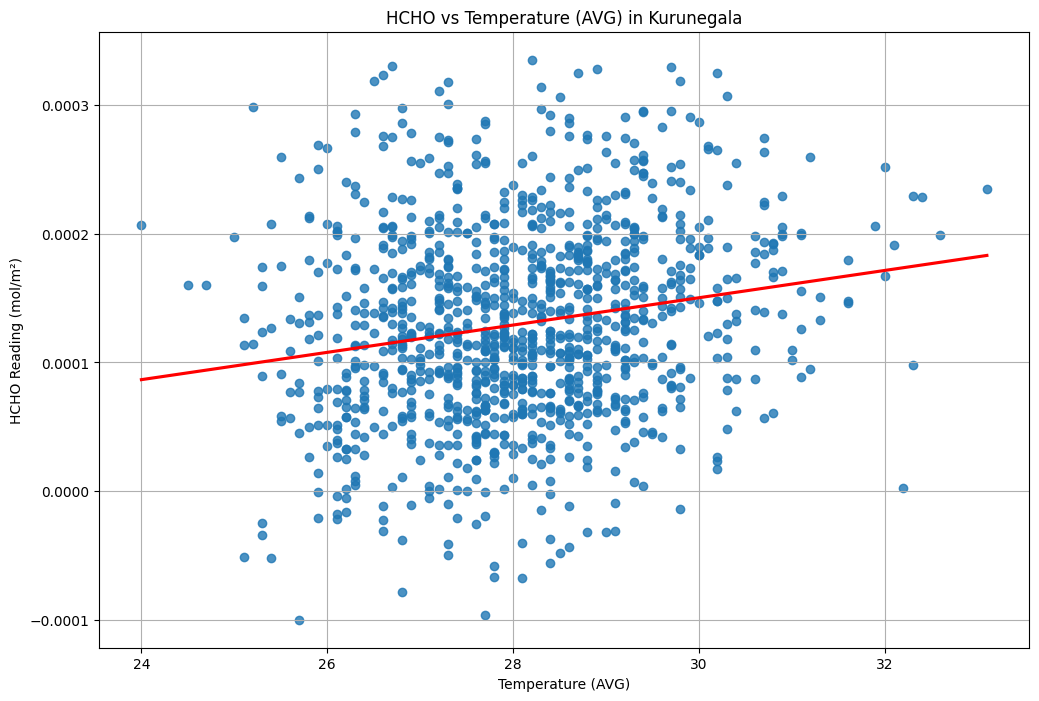

In [123]:
# Plot HCHO vs TEMPAVG for each year for Kurunegala
plt.figure(figsize=(12, 8))
sns.regplot(data=merged_kurunegala, x='TEMPAVG', y='HCHO reading', scatter=True, ci=None, line_kws={"color": "red"})
plt.title('HCHO vs Temperature (AVG) in Kurunegala')
plt.xlabel('Temperature (AVG)')
plt.ylabel('HCHO Reading (mol/m²)')
plt.grid(True)
plt.show()


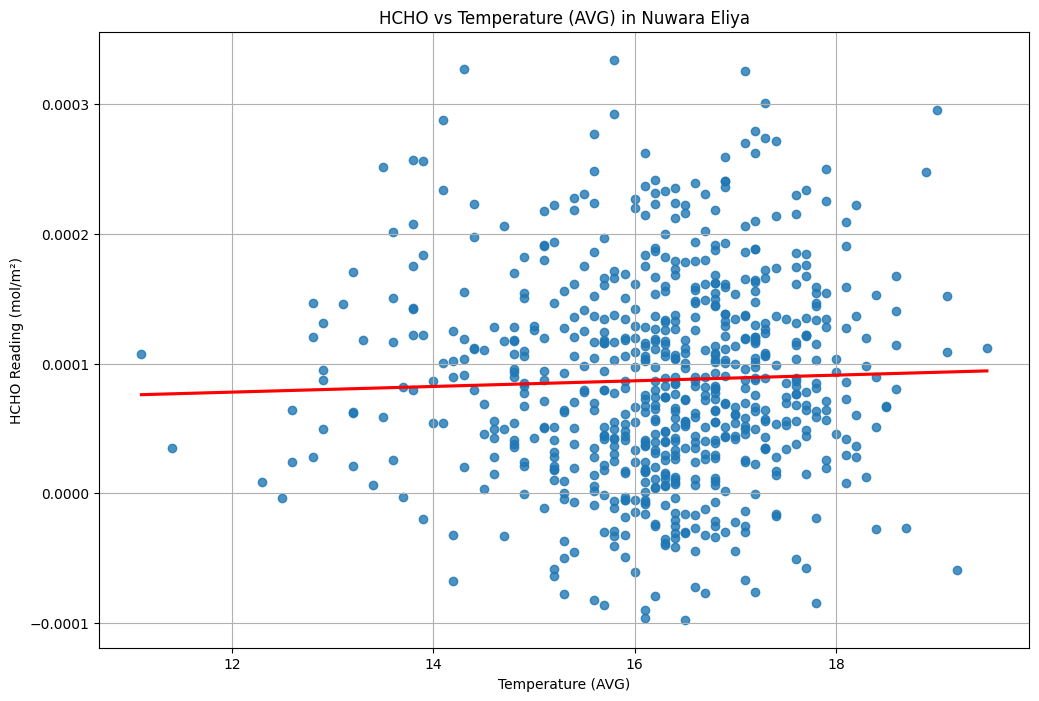

In [124]:
# Plot HCHO vs TEMPAVG for each year for Nuwara Eliya
plt.figure(figsize=(12, 8))
sns.regplot(data=merged_nuwara_eliya, x='TEMPAVG', y='HCHO reading', scatter=True, ci=None, line_kws={"color": "red"})
plt.title('HCHO vs Temperature (AVG) in Nuwara Eliya')
plt.xlabel('Temperature (AVG)')
plt.ylabel('HCHO Reading (mol/m²)')
plt.grid(True)
plt.show()

In [125]:
merged_colombo.set_index('Date', inplace=True)
merged_nuwara_eliya.set_index('Date', inplace=True)
merged_kurunegala.set_index('Date', inplace=True)

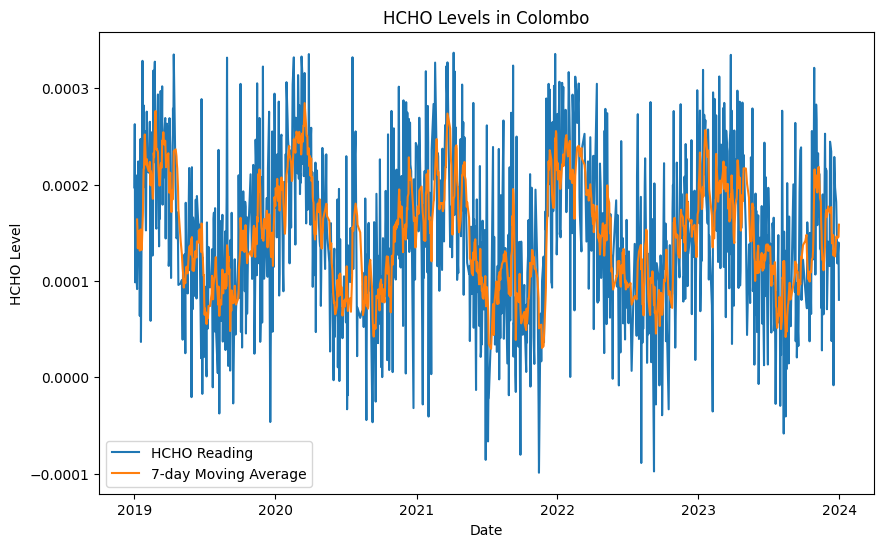

In [126]:
merged_colombo['7-day MA'] = merged_colombo['HCHO reading'].rolling(window=7).mean()

# Plot HCHO readings and moving averages
plt.figure(figsize=(10, 6))
plt.plot(merged_colombo.index, merged_colombo['HCHO reading'], label='HCHO Reading')
plt.plot(merged_colombo.index, merged_colombo['7-day MA'], label='7-day Moving Average')
plt.title('HCHO Levels in Colombo')
plt.xlabel('Date')
plt.ylabel('HCHO Level')
plt.legend()
plt.show()

<Figure size 640x480 with 0 Axes>

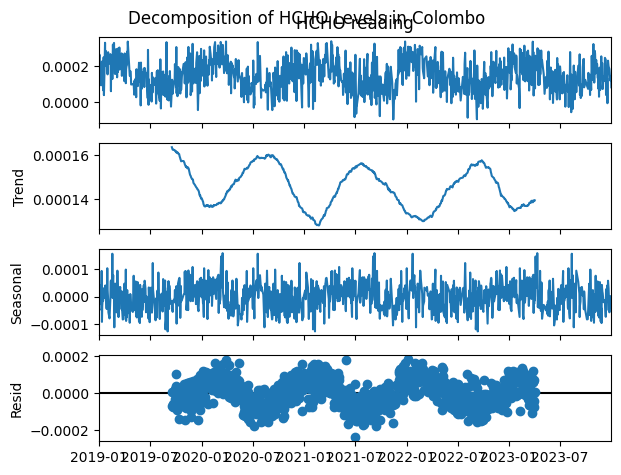

<Figure size 640x480 with 0 Axes>

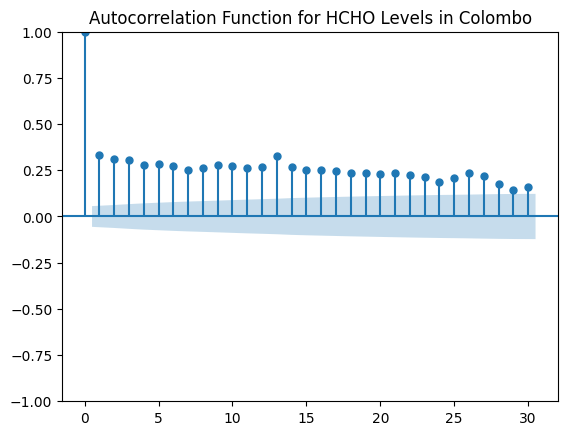

In [127]:

plt.subplots_adjust(hspace=0.5)
# Decomposition
decomposition = seasonal_decompose(merged_colombo['HCHO reading'], model='additive', period=365)
decomposition.plot()
plt.suptitle("Decomposition of HCHO Levels in Colombo")
plt.show()
plt.subplots_adjust(hspace=0.5)
# ACF plot
plot_acf(merged_colombo['HCHO reading'], lags=30)
plt.title("Autocorrelation Function for HCHO Levels in Colombo")
plt.show()

In [128]:
print(merged_colombo.head())

            HCHO reading     Location  Month  PRCP  TEMPAVG  Year  7-day MA
Date                                                                       
2019-01-01      0.000197  colombo, ce      1   0.0     27.5  2019       NaN
2019-01-02      0.000263  colombo, ce      1   0.0     25.8  2019       NaN
2019-01-03      0.000099  colombo, ce      1   0.0     27.1  2019       NaN
2019-01-04      0.000210  colombo, ce      1   0.0     27.1  2019       NaN
2019-01-05      0.000179  colombo, ce      1   0.0     27.2  2019       NaN


In [129]:
# Altitude, Population and Population density
moredata = pd.read_csv("/content/drive/MyDrive/My CW/DE CW/CM2606-CW/PopulationAltitudeOfCitiesInSriLanka.csv", names=["Location", "Year", "Population", "Population Density","Altitude"])

print(moredata.head())

         Location  Year  Population  Population Density  Altitude
0  Colombo Proper  2019      650000               15000         4
1  Colombo Proper  2020      670000               15500         4
2  Colombo Proper  2021      690000               16000         4
3  Colombo Proper  2022      710000               16500         4
4  Colombo Proper  2023      730000               17000         4


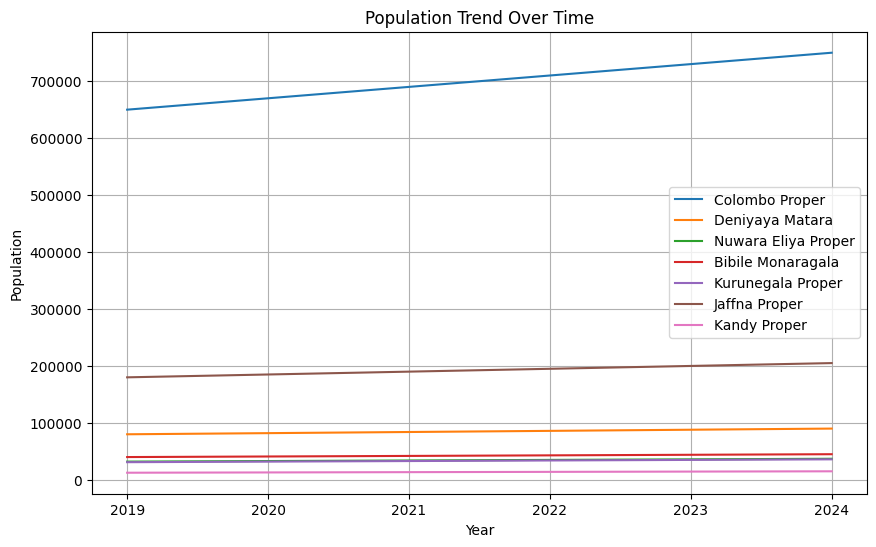

In [130]:
# Line Graph
plt.figure(figsize=(10, 6))
for city in moredata['Location'].unique():
    city_data = moredata[moredata['Location'] == city]
    plt.plot(city_data['Year'], city_data['Population'], label=city)
plt.title('Population Trend Over Time')
plt.xlabel('Year')
plt.ylabel('Population')
plt.legend()
plt.grid(True)
plt.show()

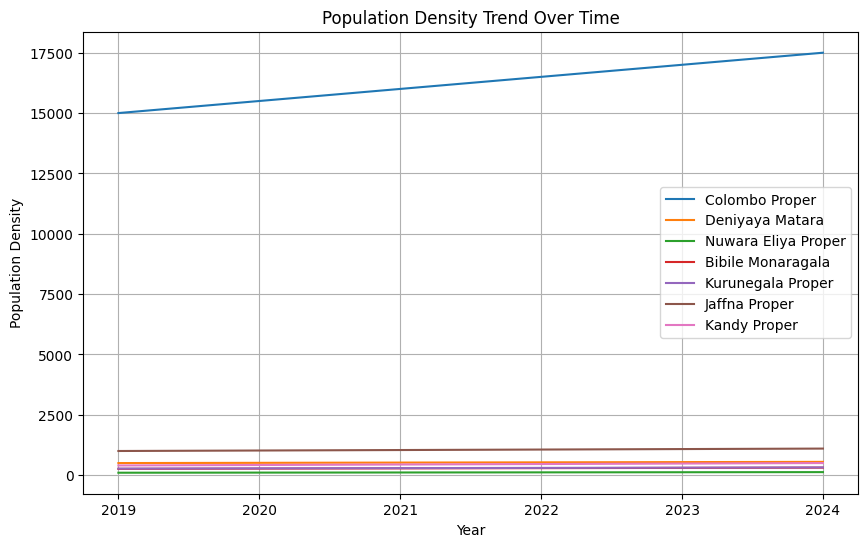

In [131]:
# Line Graph
plt.figure(figsize=(10, 6))
for city in moredata['Location'].unique():
    city_data = moredata[moredata['Location'] == city]
    plt.plot(city_data['Year'], city_data['Population Density'], label=city)
plt.title('Population Density Trend Over Time')
plt.xlabel('Year')
plt.ylabel('Population Density')
plt.legend()
plt.grid(True)
plt.show()

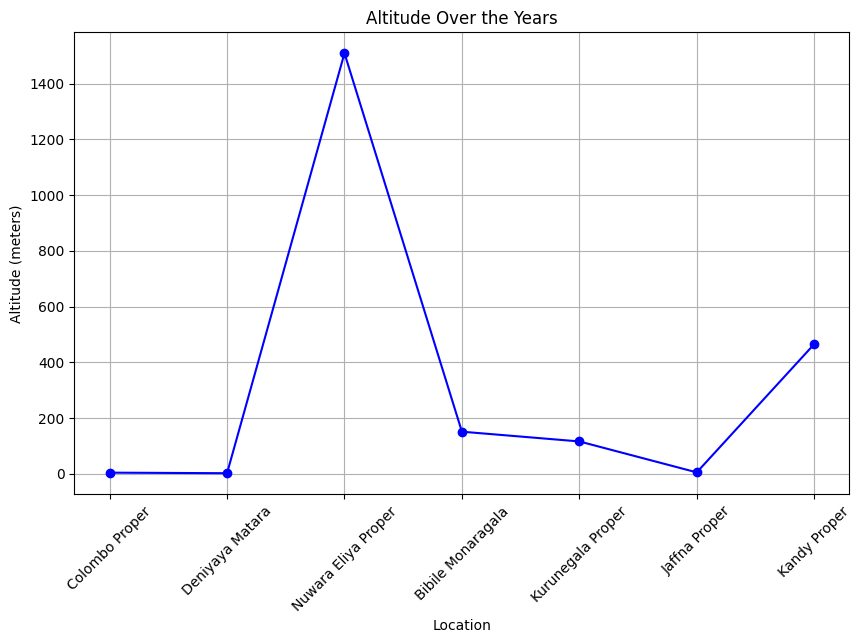

In [132]:
# Get unique locations and their altitudes
unique_locations = moredata['Location'].unique()
altitudes = [moredata[moredata['Location'] == location]['Altitude'].iloc[0] for location in unique_locations]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(unique_locations, altitudes, marker='o', linestyle='-', color='b')
plt.title('Altitude Over the Years')
plt.xlabel('Location')
plt.ylabel('Altitude (meters)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [133]:
moredata["Location"] = moredata["Location"].str.lower()

In [134]:
print(moredata.head())

         Location  Year  Population  Population Density  Altitude
0  colombo proper  2019      650000               15000         4
1  colombo proper  2020      670000               15500         4
2  colombo proper  2021      690000               16000         4
3  colombo proper  2022      710000               16500         4
4  colombo proper  2023      730000               17000         4


In [135]:
location_mapping = {
    "colombo proper": "colombo, ce",
    "kurunegala proper": "kurunegala, ce",
    "nuwara eliya proper": "nuwara eliya, ce"
}

moredata['Location'] = moredata['Location'].map(location_mapping)

In [136]:
merged_colombo.reset_index(inplace=True)
merged_kurunegala.reset_index(inplace=True)
merged_nuwara_eliya.reset_index(inplace=True)

In [137]:
print(merged_colombo.head())

        Date  HCHO reading     Location  Month  PRCP  TEMPAVG  Year  7-day MA
0 2019-01-01      0.000197  colombo, ce      1   0.0     27.5  2019       NaN
1 2019-01-02      0.000263  colombo, ce      1   0.0     25.8  2019       NaN
2 2019-01-03      0.000099  colombo, ce      1   0.0     27.1  2019       NaN
3 2019-01-04      0.000210  colombo, ce      1   0.0     27.1  2019       NaN
4 2019-01-05      0.000179  colombo, ce      1   0.0     27.2  2019       NaN


In [138]:
# moredata['Year'] = pd.to_datetime(moredata['Year'], format='%Y')
# merged_colombo['Year'] = pd.to_datetime(merged_colombo['Year'], format='%Y')
# merged_kurunegala['Year'] = pd.to_datetime(merged_kurunegala['Year'], format='%Y')
# merged_nuwara_eliya['Year'] = pd.to_datetime(merged_nuwara_eliya['Year'], format='%Y')

merged_colombo_final = pd.merge(merged_colombo, moredata[moredata['Location'] == 'colombo, ce'], on=['Location', 'Year'], how='left')
merged_kurunegala_final = pd.merge(merged_kurunegala, moredata[moredata['Location'] == 'kurunegala, ce'], on=['Location', 'Year'], how='left')
merged_nuwara_eliya_final = pd.merge(merged_nuwara_eliya, moredata[moredata['Location'] == 'nuwara eliya, ce'], on=['Location', 'Year'], how='left')

In [139]:
print(merged_colombo_final.head())

        Date  HCHO reading     Location  Month  PRCP  TEMPAVG  Year  7-day MA  \
0 2019-01-01      0.000197  colombo, ce      1   0.0     27.5  2019       NaN   
1 2019-01-02      0.000263  colombo, ce      1   0.0     25.8  2019       NaN   
2 2019-01-03      0.000099  colombo, ce      1   0.0     27.1  2019       NaN   
3 2019-01-04      0.000210  colombo, ce      1   0.0     27.1  2019       NaN   
4 2019-01-05      0.000179  colombo, ce      1   0.0     27.2  2019       NaN   

   Population  Population Density  Altitude  
0      650000               15000         4  
1      650000               15000         4  
2      650000               15000         4  
3      650000               15000         4  
4      650000               15000         4  


In [140]:
print(merged_colombo_final)

           Date  HCHO reading     Location  Month  PRCP  TEMPAVG  Year  \
0    2019-01-01      0.000197  colombo, ce      1   0.0     27.5  2019   
1    2019-01-02      0.000263  colombo, ce      1   0.0     25.8  2019   
2    2019-01-03      0.000099  colombo, ce      1   0.0     27.1  2019   
3    2019-01-04      0.000210  colombo, ce      1   0.0     27.1  2019   
4    2019-01-05      0.000179  colombo, ce      1   0.0     27.2  2019   
...         ...           ...          ...    ...   ...      ...   ...   
1213 2023-12-21      0.000197  colombo, ce     12  20.1     27.3  2023   
1214 2023-12-24      0.000182  colombo, ce     12   1.0     28.1  2023   
1215 2023-12-27      0.000118  colombo, ce     12   0.0     28.8  2023   
1216 2023-12-30      0.000140  colombo, ce     12   2.5     27.1  2023   
1217 2023-12-31      0.000080  colombo, ce     12   8.4     27.5  2023   

      7-day MA  Population  Population Density  Altitude  
0          NaN      650000               15000      

In [141]:
print("Merged Colombo Data:")
print(merged_colombo_final)
print("\nMerged Kurunegala Data:")
print(merged_kurunegala_final)
print("\nMerged Nuwara Eliya Data:")
print(merged_nuwara_eliya_final)

Merged Colombo Data:
           Date  HCHO reading     Location  Month  PRCP  TEMPAVG  Year  \
0    2019-01-01      0.000197  colombo, ce      1   0.0     27.5  2019   
1    2019-01-02      0.000263  colombo, ce      1   0.0     25.8  2019   
2    2019-01-03      0.000099  colombo, ce      1   0.0     27.1  2019   
3    2019-01-04      0.000210  colombo, ce      1   0.0     27.1  2019   
4    2019-01-05      0.000179  colombo, ce      1   0.0     27.2  2019   
...         ...           ...          ...    ...   ...      ...   ...   
1213 2023-12-21      0.000197  colombo, ce     12  20.1     27.3  2023   
1214 2023-12-24      0.000182  colombo, ce     12   1.0     28.1  2023   
1215 2023-12-27      0.000118  colombo, ce     12   0.0     28.8  2023   
1216 2023-12-30      0.000140  colombo, ce     12   2.5     27.1  2023   
1217 2023-12-31      0.000080  colombo, ce     12   8.4     27.5  2023   

      7-day MA  Population  Population Density  Altitude  
0          NaN      650000     

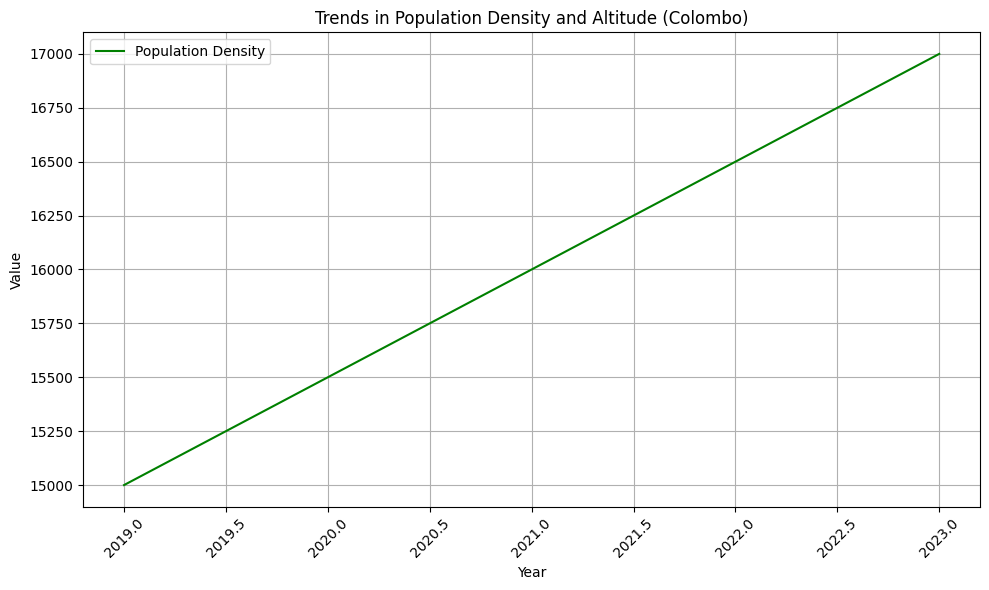

In [142]:
# Group the data by year and calculate the mean values
grouped_data = merged_colombo_final.groupby('Year').agg({'Population Density': 'mean', 'Altitude': 'mean'})

# Plot trends
plt.figure(figsize=(10, 6))

# Plot population density trend
plt.plot(grouped_data.index, grouped_data['Population Density'], label='Population Density', color='green')


plt.title('Trends in Population Density and Altitude (Colombo)')
plt.xlabel('Year')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

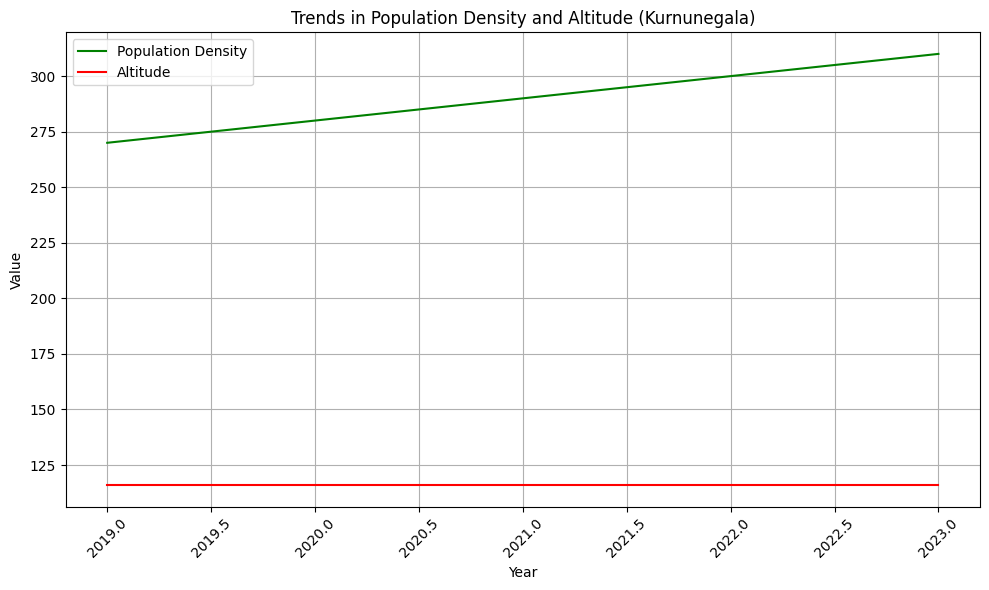

In [143]:
# Group the data by year and calculate the mean values
grouped_data = merged_kurunegala_final.groupby('Year').agg({'Population Density': 'mean', 'Altitude': 'mean'})

# Plot trends
plt.figure(figsize=(10, 6))

# Plot population density trend
plt.plot(grouped_data.index, grouped_data['Population Density'], label='Population Density', color='green')

# Plot altitude trend
plt.plot(grouped_data.index, grouped_data['Altitude'], label='Altitude', color='red')

plt.title('Trends in Population Density and Altitude (Kurnunegala)')
plt.xlabel('Year')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

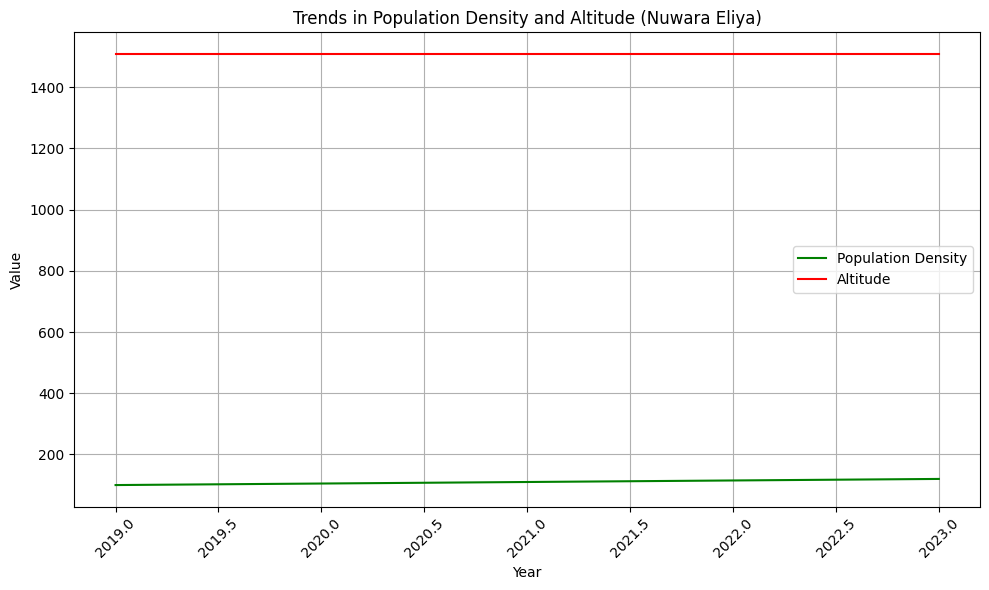

In [144]:
# Group the data by year and calculate the mean values
grouped_data = merged_nuwara_eliya_final.groupby('Year').agg({'Population Density': 'mean', 'Altitude': 'mean'})

# Plot trends
plt.figure(figsize=(10, 6))

# Plot population density trend
plt.plot(grouped_data.index, grouped_data['Population Density'], label='Population Density', color='green')

# Plot altitude trend
plt.plot(grouped_data.index, grouped_data['Altitude'], label='Altitude', color='red')

plt.title('Trends in Population Density and Altitude (Nuwara Eliya)')
plt.xlabel('Year')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [145]:
merged_colombo_final.to_csv('finalmerged_colombo.csv', index=False)
merged_kurunegala_final.to_csv('finalmerged_kurunegala.csv', index=False)
merged_nuwara_eliya_final.to_csv('finalmerged_nuwaraeliya.csv', index=False)

MACHINE LEARNING

In [146]:
print("Merged Colombo Data:")
print(merged_colombo_final)
print("\nMerged Kurunegala Data:")
print(merged_kurunegala_final)
print("\nMerged Nuwara Eliya Data:")
print(merged_nuwara_eliya_final)

Merged Colombo Data:
           Date  HCHO reading     Location  Month  PRCP  TEMPAVG  Year  \
0    2019-01-01      0.000197  colombo, ce      1   0.0     27.5  2019   
1    2019-01-02      0.000263  colombo, ce      1   0.0     25.8  2019   
2    2019-01-03      0.000099  colombo, ce      1   0.0     27.1  2019   
3    2019-01-04      0.000210  colombo, ce      1   0.0     27.1  2019   
4    2019-01-05      0.000179  colombo, ce      1   0.0     27.2  2019   
...         ...           ...          ...    ...   ...      ...   ...   
1213 2023-12-21      0.000197  colombo, ce     12  20.1     27.3  2023   
1214 2023-12-24      0.000182  colombo, ce     12   1.0     28.1  2023   
1215 2023-12-27      0.000118  colombo, ce     12   0.0     28.8  2023   
1216 2023-12-30      0.000140  colombo, ce     12   2.5     27.1  2023   
1217 2023-12-31      0.000080  colombo, ce     12   8.4     27.5  2023   

      7-day MA  Population  Population Density  Altitude  
0          NaN      650000     

In [147]:
columns_to_remove = ['Month', 'Year']
merged_colombo_final.drop(columns=columns_to_remove, inplace=True)
merged_kurunegala_final.drop(columns=columns_to_remove, inplace=True)
merged_nuwara_eliya_final.drop(columns=columns_to_remove, inplace=True)

In [153]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Load data for Colombo
colombo_data = merged_colombo_final.copy()

# Preprocess the data
colombo_data['Date'] = pd.to_datetime(colombo_data['Date'])
colombo_data.set_index('Date', inplace=True)

# remove negative values
colombo_data.loc[colombo_data['HCHO reading'] < 0, 'HCHO reading'] = np.nan

# Interpolate or fill NaN values
colombo_data['HCHO reading'].interpolate(method='linear', inplace=True)

# Interpolate missing values
colombo_data = colombo_data.interpolate(method='linear')

# Ensure daily frequency
colombo_data = colombo_data.asfreq('D')

# Filter data from 2019-01-01
colombo_data = colombo_data['2019-01-01':]

# Split the data into training and testing sets
train_size = int(len(colombo_data) * 0.8)  # 80% for training
train_data = colombo_data.iloc[:train_size]
test_data = colombo_data.iloc[train_size:]

# Drop rows with missing values in training data
train_data = train_data.dropna()

# Replace infinite values with NaN in training data
train_data.replace([np.inf, -np.inf], np.nan, inplace=True)

# Drop rows with NaN values in training data
train_data = train_data.dropna()

# Drop rows with missing values in testing data
test_data = test_data.dropna()

# Replace infinite values with NaN in testing data
test_data.replace([np.inf, -np.inf], np.nan, inplace=True)

# Drop rows with NaN values in testing data
test_data = test_data.dropna()

# Define exogenous variables
exog_vars = ['PRCP', 'TEMPAVG', 'Population', 'Population Density', 'Altitude']

# Implement Time Series Cross-Validation
window_size = 30  # Number of days in each training window
forecast_steps = len(test_data)  # Number of steps to forecast

# Initialize lists to store predictions and actual values
predictions = []
actuals = []

# Perform Time Series Cross-Validation
for i in range(len(test_data) - forecast_steps + 1):
    # Define training and testing data for the current window
    train_window = train_data.iloc[:train_size + i]
    test_window = test_data.iloc[i:i + forecast_steps]

    # Fit SARIMA model with exogenous variables for the current window
    model = SARIMAX(train_window['HCHO reading'], exog=train_window[exog_vars], order=(2, 0, 2), seasonal_order=(1, 1, 1, 12))
    result = model.fit()

    # Forecast future values for the current window
    forecast = result.forecast(steps=forecast_steps, exog=test_window[exog_vars])

    # Append predictions and actual values to lists
    predictions.append(forecast)
    actuals.append(test_window['HCHO reading'])

# Concatenate predictions and actual values
predictions = np.concatenate(predictions)
actuals = np.concatenate(actuals)

# Calculate evaluation metrics (e.g., Mean Squared Error)
mse = mean_squared_error(actuals, predictions)
print("Mean Squared Error:", mse)

# Optionally, you can also print the model summary
print(result.summary())

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Mean Squared Error: 5.5998873797906e-09
                                      SARIMAX Results                                       
Dep. Variable:                         HCHO reading   No. Observations:                  964
Model:             SARIMAX(2, 0, 2)x(1, 1, [1], 12)   Log Likelihood                7663.192
Date:                              Sat, 20 Apr 2024   AIC                         -15302.385
Time:                                      21:13:37   BIC                         -15244.082
Sample:                                           0   HQIC                        -15280.173
                                              - 964                                         
Covariance Type:                                opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PRCP               -5.507e-08    3.1e-07  

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


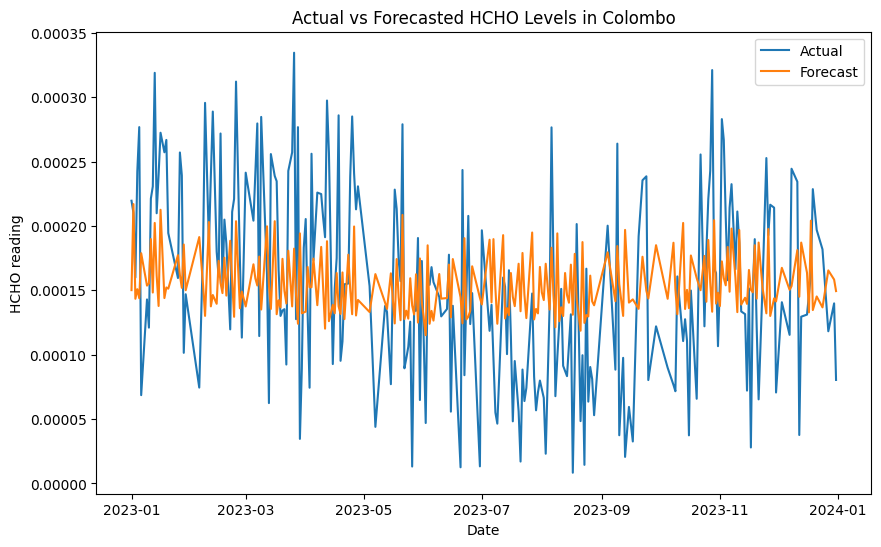

In [154]:
# Plot actual vs forecasted values
plt.figure(figsize=(10, 6))
plt.plot(test_data.index, test_data['HCHO reading'], label='Actual')
plt.plot(test_data.index, forecast, label='Forecast')
plt.title('Actual vs Forecasted HCHO Levels in Colombo')
plt.xlabel('Date')
plt.ylabel('HCHO reading')
plt.legend()
plt.show()

In [157]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate forecast errors
forecast_errors = test_data['HCHO reading'] - forecast

# Calculate evaluation metrics
mae = mean_absolute_error(test_data['HCHO reading'], forecast)
mse = mean_squared_error(test_data['HCHO reading'], forecast)
rmse = np.sqrt(mse)
mape = np.mean(np.abs(forecast_errors / test_data['HCHO reading'])) * 100

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)

Mean Absolute Error (MAE): 6.260441513935434e-05
Mean Squared Error (MSE): 5.5998873797906e-09
Root Mean Squared Error (RMSE): 7.483239525626986e-05


<ipython-input-157-377eb87b20a6>:11: RuntimeWarning: '<' not supported between instances of 'int' and 'Timestamp', sort order is undefined for incomparable objects.
  mape = np.mean(np.abs(forecast_errors / test_data['HCHO reading'])) * 100
